# Adult Census Income — Deep Learning Assessment

## Objective
Predict whether a person earns more than $50,000 per year
using their census attributes.

## Problem type
Supervised binary classification.

## Target
The income column:
- <=50K: annual income of $50,000 or less
- >50K: annual income above $50,000

## Assessment approach
Train and compare at least three neural network models.
Track experiments in MLflow.
Select the best model using validation evidence, then evaluate
it on a separate test set.

## Dataset scope
The supplied adult.csv contains 32,561 rows and 15 columns.
Results describe patterns in this dataset; they do not establish
that a particular attribute causes higher or lower income.

In [1]:
import pandas as pd

# Load the CSV into a DataFrame: a table we can inspect in Python
df = pd.read_csv("adult.csv")

# Check how much data we loaded
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display a small preview
df.head()

Number of rows: 32561
Number of columns: 15


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [2]:
# Show column names, non-missing counts and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


## Step 3 — Identify Missing Values

Some census records contain `?` for unknown information.

Think of an application form where someone writes `?` under occupation.
The box contains text, but it does not provide a usable answer.

### What we will do
1. Remove spaces from the beginning and end of text values.
2. Replace `?` with a proper missing-value marker.
3. Count missing values and calculate their percentage in each column.

### Why?
Pandas treats `?` as text rather than missing information. Without this
change, our preparation code could treat it as an actual occupation
or employment category.

### Decision and alternative
We will measure missingness before deciding how to handle it.
Immediately dropping affected rows could discard useful information.

No rows are removed or missing values filled in this step.

### Assessment explanation
“We identified unknown values stored as question marks and converted
them into recognised missing values. This allowed us to measure
missingness correctly before choosing a treatment.”

In [2]:
# Remove leading and trailing spaces from text values
text_columns = df.select_dtypes(
    include=["object", "str", "string"]
).columns

for column in text_columns:
    df[column] = df[column].str.strip()

# Convert question marks into missing values
df = df.replace("?", pd.NA)

# Calculate missing counts and percentages
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2)
})

# Display only columns that have missing values
missing_summary[missing_summary["Missing count"] > 0].sort_values(
    by="Missing count",
    ascending=False
)

,Missing count,Missing percentage
occupation,1843,5.66
workclass,1836,5.64
native.country,583,1.79


## Step 4 — Check for Duplicate Records

Imagine finding two application forms with exactly the same details.
They might be an accidental copy, or they might describe two different
people with matching attributes.

### What we will do
Count rows where every column matches an earlier row, then inspect
some examples.

### Why?
Repeated records can give certain examples extra influence during
training. If copies appear across training and test sets, evaluation
may also look better than it should.

### Decision and alternative
We will inspect duplicates before removing them.
Matching attributes alone do not prove that records belong to the
same person, because this dataset has no unique person identifier.

### Assessment explanation
“We checked for exact duplicate rows to understand possible repetition
and its effect on training and evaluation. We inspected the records
before deciding how to handle them.”

In [3]:
# Count repeated rows beyond their first occurrence
duplicate_count = df.duplicated().sum()

print("Repeated rows beyond the first occurrence:", duplicate_count)

# Show matching records together, including their first occurrence
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.sort_values(
    by=list(df.columns),
    na_position="last"
).head(10)

Repeated rows beyond the first occurrence: 24


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
19622,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
20507,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
10307,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
22783,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
17456,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
22934,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
7615,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
32065,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
9269,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
14346,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K


## Step 4 — Handle Exact Duplicate Rows

### Finding
We found 24 repeated rows beyond their first occurrence,
approximately 0.07% of the dataset.

### Decision
Keep the first occurrence of each exact row and remove later copies
before creating the training, validation and test sets.

### Why?
Imagine practising with a question and then receiving the identical
question in an exam. It provides less convincing evidence that you
can handle something new.

Removing exact repeats prevents identical records from appearing
across our data splits.

### Alternative and limitation
We could retain matching records and keep them in the same split.
Matching attributes do not prove they describe the same person,
because the dataset has no unique person identifier.

For this assessment, we treat exact repeats as redundant records.
Only a very small proportion of rows is affected.

### Assessment explanation
“We removed 24 exact repeated rows before splitting the data to
prevent identical records appearing across the data splits.
We documented that these were matching records, rather than
confirmed duplicate people.”

In [4]:
# Record the size before removing exact repeats
rows_before = len(df)

# Keep one copy of each exact row
df = df.drop_duplicates().reset_index(drop=True)

# Verify the result
print("Rows removed:", rows_before - len(df))
print("Rows remaining:", len(df))
print("Remaining exact duplicates:", df.duplicated().sum())

Rows removed: 24
Rows remaining: 32537
Remaining exact duplicates: 0


## Step 5 — Inspect Numerical Values

### What we will do
Summarise the numerical columns to inspect their ranges,
typical values and variation.

### Everyday example
Imagine checking employee forms:
- An age of -5 suggests an error.
- An age of 90 is unusual but possible.
- A large investment gain may also be genuine.

We should distinguish impossible values from uncommon values.

### Why?
Incorrect values can affect training. However, automatically removing
unusual values could discard useful examples, especially when
predicting higher income.

### Decision
Inspect the numerical summaries before deciding whether any values
need further investigation or treatment.

We will not automatically remove values using an outlier rule.
Any limits calculated from the data will be fitted using training
data only after we create our splits.

### How to read the summary
- count: number of non-missing values
- mean: average
- std: how spread out the values are
- min: smallest value
- 25%: one quarter of values are at or below this value
- 50%: median, or middle value
- 75%: three quarters of values are at or below this value
- max: largest value

### Assessment explanation
“We inspected numerical ranges to identify possible errors and
unusual values. We did not assume that every extreme value was
incorrect, because genuine high capital gains or long working
hours may be relevant to income prediction.”

In [5]:
# Summarise numerical columns
# Transpose so each feature appears on its own row
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32537.0,38.59,13.64,17.0,28.0,37.0,48.0,90.0
fnlwgt,32537.0,189780.85,105556.47,12285.0,117827.0,178356.0,236993.0,1484705.0
education.num,32537.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital.gain,32537.0,1078.44,7387.96,0.0,0.0,0.0,0.0,99999.0
capital.loss,32537.0,87.37,403.10,0.0,0.0,0.0,0.0,4356.0
hours.per.week,32537.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0


## Step 5 — Numerical Findings and Validity Checks

### Findings
- Age ranges from 17 to 90.
- Weekly working hours range from 1 to 99.
- Median weekly working hours are 40.
- Capital gains and losses are zero for most records.
- Numerical features have considerably different scales.

### Decision and reasoning
We will retain unusual values for now because being uncommon does
not make them incorrect. Removing high capital gains could remove
information relevant to predicting higher income.

We will later scale numerical inputs to help neural network training.
Scaling changes their scale; it does not remove unusual observations.

### Further check
We will count values that violate basic validity rules:
- Age must be positive.
- Working hours must be positive and cannot exceed 168 hours per week.
- Capital gains and losses must not be negative.
- Census weights must be positive.

These checks detect obvious problems; passing them does not prove
that every record is accurate.

### Assessment explanation
“We retained extreme numerical values because we had no evidence
that they were errors. We checked basic validity rules and planned
to scale numerical features during preprocessing.”

In [6]:
# Count values that violate basic validity rules
invalid_counts = pd.Series({
    "Age zero or negative": (df["age"] <= 0).sum(),
    "Weekly hours zero or negative": (df["hours.per.week"] <= 0).sum(),
    "Weekly hours above 168": (df["hours.per.week"] > 168).sum(),
    "Negative capital gain": (df["capital.gain"] < 0).sum(),
    "Negative capital loss": (df["capital.loss"] < 0).sum(),
    "Census weight zero or negative": (df["fnlwgt"] <= 0).sum()
}, name="Invalid count")

invalid_counts.to_frame()

,Invalid count
Age zero or negative,0
Weekly hours zero or negative,0
Weekly hours above 168,0
Negative capital gain,0
Negative capital loss,0
Census weight zero or negative,0


## Step 5 — Numerical Findings and Validity Checks

### Findings
- Age ranges from 17 to 90.
- Weekly working hours range from 1 to 99.
- Median weekly working hours are 40.
- Capital gains and losses are zero for most records.
- Numerical features have considerably different scales.

### Decision and reasoning
We will retain unusual values for now because being uncommon does
not make them incorrect. Removing high capital gains could remove
information relevant to predicting higher income.

We will later scale numerical inputs to help neural network training.
Scaling changes their scale; it does not remove unusual observations.

### Further check
We will count values that violate basic validity rules:
- Age must be positive.
- Working hours must be positive and cannot exceed 168 hours per week.
- Capital gains and losses must not be negative.
- Census weights must be positive.

These checks detect obvious problems; passing them does not prove
that every record is accurate.

### Assessment explanation
“We retained extreme numerical values because we had no evidence
that they were errors. We checked basic validity rules and planned
to scale numerical features during preprocessing.”

In [7]:
# Count values that violate basic validity rules
invalid_counts = pd.Series({
    "Age zero or negative": (df["age"] <= 0).sum(),
    "Weekly hours zero or negative": (df["hours.per.week"] <= 0).sum(),
    "Weekly hours above 168": (df["hours.per.week"] > 168).sum(),
    "Negative capital gain": (df["capital.gain"] < 0).sum(),
    "Negative capital loss": (df["capital.loss"] < 0).sum(),
    "Census weight zero or negative": (df["fnlwgt"] <= 0).sum()
}, name="Invalid count")

invalid_counts.to_frame()

,Invalid count
Age zero or negative,0
Weekly hours zero or negative,0
Weekly hours above 168,0
Negative capital gain,0
Negative capital loss,0
Census weight zero or negative,0


## Step 6 — Create Training, Validation and Test Sets

### Decision
Split the data into approximately:
- 70% training
- 15% validation
- 15% testing

### Why three sets?
Training data teaches the model.
Validation data helps us choose models and training settings.
Test data provides a final evaluation after those choices are made.

Repeatedly choosing models based on test results would make the
test set part of our decision-making process and weaken its value
as an independent check.

### Why 70/15/15?
This gives most records to learning while keeping several thousand
records each for validation and testing.

It is a reasonable starting choice, not a universally best ratio.
An 80/10/10 split would provide more training examples but smaller
evaluation sets.

### Why stratify?
Stratification keeps approximately the same proportion of both
income categories in each set.

It preserves the existing balance; it does not make the classes equal.

### Why random_state=42?
A fixed seed makes the split reproducible for the same input data.
The number 42 has no special modelling advantage.

### Target encoding
- <=50K becomes 0
- >50K becomes 1

These numbers are labels for the two classes, not salary amounts.

### Preventing data leakage
We split before learning preprocessing settings or exploring
relationships that will guide modelling decisions.

Scalers and encoders will be fitted on training data only.
Further exploratory analysis will use the training set.

### Assessment explanation
“We used a stratified 70/15/15 split so the model could learn,
be compared with alternatives, and receive a separate final
evaluation. All experiments will use the same splits for consistency.”

In [8]:
from sklearn.model_selection import train_test_split

# Validate the target before converting it to numbers
assert df["income"].notna().all(), "The target contains missing values."
assert set(df["income"].unique()) == {"<=50K", ">50K"}, \
    "Unexpected income labels found."

# Separate the inputs from the answer
X = df.drop(columns="income")
y = df["income"].map({"<=50K": 0, ">50K": 1}).astype("int32")

# Keep 70% for training and reserve 30% for evaluation
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Divide the reserved 30% equally: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))
print("Total rows:", len(X_train) + len(X_val) + len(X_test))

Training rows: 22775
Validation rows: 4881
Test rows: 4881
Total rows: 32537


## Step 7 — Check the Training Target Balance

### What we will do
Count how many training records belong to each income category:
- 0: income at or below $50,000
- 1: income above $50,000

### Everyday example
Imagine a classroom with 80 students wearing blue and 20 wearing red.
Someone who always guesses “blue” would be correct 80% of the time,
despite never recognising a student wearing red.

A classifier can behave similarly when one income category is
much more common.

### Why?
Class balance helps us interpret model performance.
High accuracy alone may hide poor performance on the smaller class.

### Decision
Inspect the training target before deciding whether class weighting
or another imbalance treatment is needed.

We will not automatically balance the data. Such treatments can
improve detection of the smaller class but may increase false alarms.

### Assessment explanation
“We examined the training class distribution to establish a simple
baseline and understand whether accuracy could be misleading.
We will also assess how well models identify the higher-income class.”

In [9]:
# Count both income categories in the training set
class_counts = y_train.value_counts().reindex([0, 1], fill_value=0)

# Build a readable summary
class_summary = pd.DataFrame({
    "Income category": ["<=50K", ">50K"],
    "Training records": class_counts.to_numpy(),
    "Percentage": (
        class_counts.to_numpy() / len(y_train) * 100
    ).round(2)
})

display(class_summary)

# Accuracy from always predicting the most common training class
majority_accuracy = class_counts.max() / len(y_train)

print(
    f"Always guessing the majority class gives "
    f"{majority_accuracy:.2%} training accuracy."
)

,Income category,Training records,Percentage
0,<=50K,17288,75.91
1,>50K,5487,24.09


Always guessing the majority class gives 75.91% training accuracy.


## Step 7 — Findings and Evaluation Decisions

### Finding
The training target is imbalanced:
- 75.91% earn at or below $50,000.
- 24.09% earn above $50,000.

Always predicting the majority class gives 75.91% training accuracy,
but identifies none of the higher-income records.

This is a training reference; we will later evaluate a proper
baseline on validation data for comparison.

### Evaluation decision
Treat income above $50,000 as the positive class.

Use validation F1 as our primary model-selection metric:
- Precision: when we predict higher income, how often are we correct?
- Recall: of the actual higher-income people, how many do we identify?
- F1: combines precision and recall into one score.

We choose F1 because we want to identify the smaller class while
also considering incorrect higher-income predictions.

No business costs have been specified, so this is a practical
assessment choice rather than a proven business optimum.

We will also report accuracy, precision, recall, ROC-AUC,
average precision (a summary of the precision-recall curve),
and a confusion matrix.

### Prediction threshold
Start with the same probability threshold of 0.5 for every model.
For example, a predicted probability of 0.7 becomes class 1.

F1 depends on this threshold. Any later threshold tuning must use
validation data, never test data.

### Imbalance treatment
Start without resampling or class weights to establish a reference.
A roughly 3:1 imbalance does not automatically require SMOTE.

If validation results show weak detection of the higher-income
class, we can test class weighting as a tracked experiment.

### Assessment explanation
“Accuracy alone was insufficient because always predicting the
majority class already achieved about 76% training accuracy.
We chose validation F1 to consider both missed higher-income
records and incorrect higher-income predictions.”

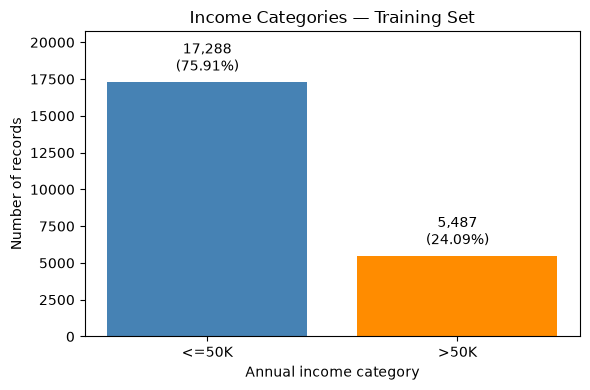

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    class_summary["Income category"],
    class_summary["Training records"],
    color=["steelblue", "darkorange"]
)

ax.bar_label(bars, labels=[
    f"{count:,}\n({percentage:.2f}%)"
    for count, percentage in zip(
        class_summary["Training records"],
        class_summary["Percentage"]
    )
], padding=5)

ax.set_title("Income Categories — Training Set")
ax.set_xlabel("Annual income category")
ax.set_ylabel("Number of records")
ax.set_ylim(0, class_summary["Training records"].max() * 1.2)

plt.tight_layout()
plt.show()

## Step 8 — Explore Age and Income

### Question
Does the proportion earning above $50,000 differ across age groups?

### Everyday example
Imagine sorting census forms into age-group folders.
In each folder, we count how many people earn above $50,000
and divide by the total number of people in that folder.

For example, if 30 out of 100 people in a group earn above
$50,000, that group's higher-income rate is 30%.

### Why use percentages rather than counts?
Age groups may contain different numbers of people.
Percentages allow a more meaningful comparison between groups.

We will also show group sizes because a percentage based on
a small group is less reliable.

### Decisions
- Use training data only to guide our exploration.
- Use age bands to make the chart easy to read.
- Keep original age values for modelling; these bands are
  for exploration only.
- Treat the bands as a presentation choice, not an optimal grouping.

### Limitation
An association between age and income does not prove that age
causes higher income. Education, occupation and other attributes
may also contribute.

### Assessment explanation
“We compared higher-income percentages across age groups rather
than raw counts, because the groups differed in size. We used
training data and retained the original age feature for modelling.”

,records,higher_income_count,Higher-income percentage
age_group,,,
17–24,3894,38,0.98
25–34,5977,1015,16.98
35–44,5722,1917,33.50
45–54,4087,1624,39.74
55–64,2198,717,32.62
65+,897,176,19.62


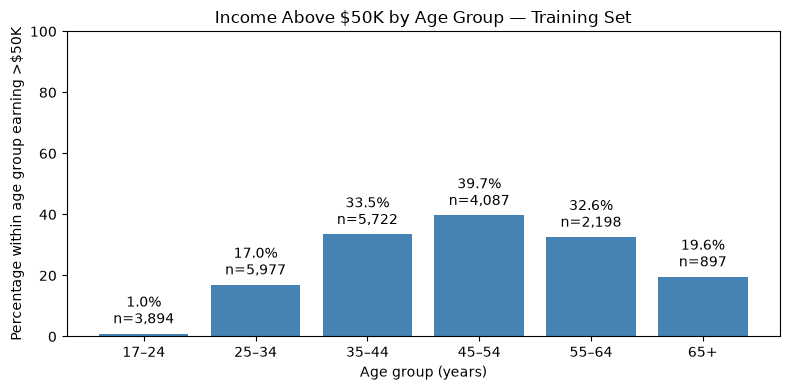

In [11]:
# Create a separate table for training-data exploration
eda_train = X_train.copy()
eda_train["income_above_50k"] = y_train

# Group ages for the chart only
age_labels = ["17–24", "25–34", "35–44", "45–54", "55–64", "65+"]

eda_train["age_group"] = pd.cut(
    eda_train["age"],
    bins=[16, 24, 34, 44, 54, 64, float("inf")],
    labels=age_labels
)

# Because the target is 0 or 1, its mean is the proportion of 1s
age_summary = (
    eda_train.groupby("age_group", observed=True)["income_above_50k"]
    .agg(records="size", higher_income_count="sum", proportion="mean")
)

age_summary["Higher-income percentage"] = (
    age_summary.pop("proportion") * 100
)

display(age_summary.round(2))

# Compare percentages, with group sizes shown above the bars
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    age_summary.index.astype(str),
    age_summary["Higher-income percentage"],
    color="steelblue"
)

ax.bar_label(
    bars,
    labels=[
        f"{percentage:.1f}%\nn={count:,}"
        for percentage, count in zip(
            age_summary["Higher-income percentage"],
            age_summary["records"]
        )
    ],
    padding=4
)

ax.set_title("Income Above $50K by Age Group — Training Set")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Percentage within age group earning >$50K")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

### Age and Income — Findings

The percentage earning above $50,000 varies by age group:

- Ages 17–24: 0.98%
- Ages 25–34: 16.98%
- Ages 35–44: 33.50%
- Ages 45–54: 39.74%
- Ages 55–64: 32.62%
- Ages 65+: 19.62%

The percentage rises through the middle age groups, peaks at
45–54, and then declines.

### Modelling implication
Age may provide useful predictive information. The observed pattern
is not a simple straight-line increase.

We will retain original age values so the neural network can learn
patterns without being restricted to our presentation age bands.

This chart does not prove that age causes higher income or establish
how much age improves predictions alongside other features.

## Step 9 — Explore Education and Income

### Question
How does the percentage earning above $50,000 vary by education?

### Why?
Education may help predict income. We need to inspect the actual
training data rather than assume the relationship.

### Decisions
- Compare percentages because education groups differ in size.
- Display record counts to identify small groups.
- Order categories by education.num to make the chart readable.
- Check whether education and education.num map one-to-one.

If both columns represent the same information, keeping both may
add unnecessary inputs. We will inspect the mapping before deciding.

### Limitation
Differences between groups show association, not proof that education
alone caused the income differences.

### Assessment explanation
“We explored income percentages by education and checked whether
the text and numerical education columns duplicated information.”

,education,education.num
13206,Preschool,1
27773,1st-4th,2
27537,5th-6th,3
3389,7th-8th,4
16051,9th,5
27022,10th,6
23286,11th,7
27868,12th,8
30864,HS-grad,9
18329,Some-college,10


Each education label has one numerical code: True
Each numerical code has one education label: True


,education.num,education,records,Higher-income percentage
0,1,Preschool,31,0.00
1,2,1st-4th,115,5.22
2,3,5th-6th,224,4.02
3,4,7th-8th,454,5.29
4,5,9th,372,4.57
5,6,10th,632,7.12
6,7,11th,818,5.26
7,8,12th,322,7.76
8,9,HS-grad,7360,15.95
9,10,Some-college,5056,19.11


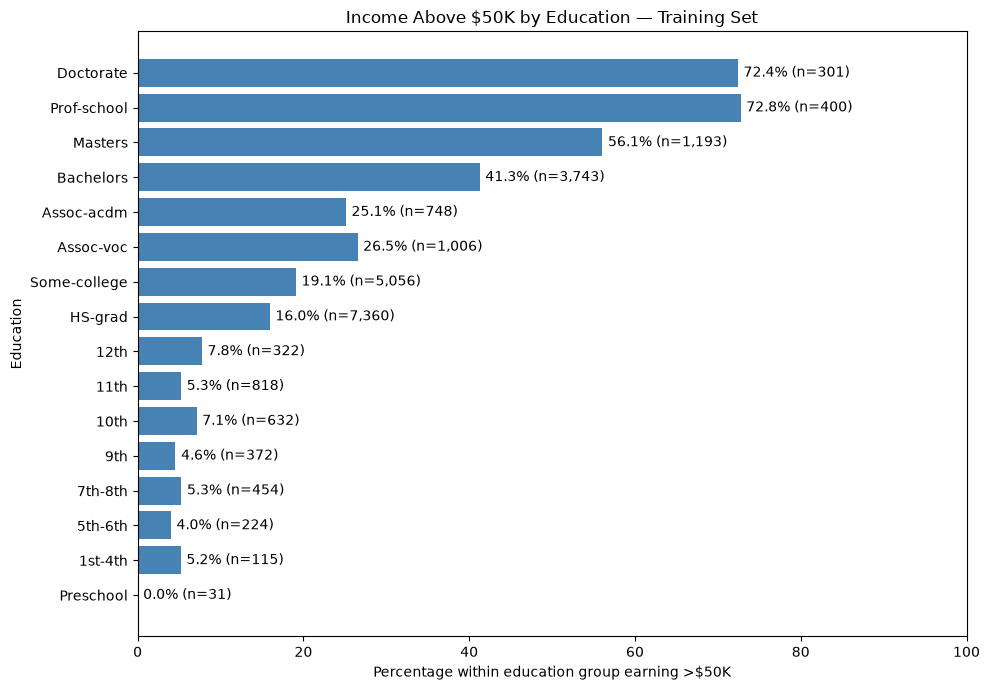

In [12]:
# Check the relationship between the two education columns
education_mapping = (
    eda_train[["education", "education.num"]]
    .drop_duplicates()
    .sort_values("education.num")
)

display(education_mapping)

print(
    "Each education label has one numerical code:",
    education_mapping["education"].is_unique
)

print(
    "Each numerical code has one education label:",
    education_mapping["education.num"].is_unique
)

# Summarise income by education, ordered by numerical code
education_summary = (
    eda_train.groupby(
        ["education.num", "education"],
        observed=True
    )["income_above_50k"]
    .agg(records="size", proportion="mean")
    .sort_index()
    .reset_index()
)

education_summary["Higher-income percentage"] = (
    education_summary.pop("proportion") * 100
)

display(education_summary.round(2))

# Use horizontal bars so education labels remain readable
fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    education_summary["education"],
    education_summary["Higher-income percentage"],
    color="steelblue"
)

ax.bar_label(
    bars,
    labels=[
        f"{percentage:.1f}% (n={count:,})"
        for percentage, count in zip(
            education_summary["Higher-income percentage"],
            education_summary["records"]
        )
    ],
    padding=4
)

ax.set_title("Income Above $50K by Education — Training Set")
ax.set_xlabel("Percentage within education group earning >$50K")
ax.set_ylabel("Education")
ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

## Step 9 — Education Findings and Feature Decision

### Findings
The training-data checks confirmed a one-to-one mapping between
education and education.num.

Examples:
- HS-grad → 9
- Bachelors → 13
- Masters → 14
- Doctorate → 16

Both columns describe the same underlying education category.

Higher-income percentages differ between education groups.
Small groups need caution: the Preschool group has only 31 records.
Its observed 0% does not establish that nobody in that category
could earn above $50,000.

### Decision
Keep education.num and remove education from the model inputs.

### Why?
The numerical code provides a compact, ordered representation
of education level.

Keeping both representations would add inputs without adding
new underlying information.

### Alternative and trade-off
We could instead keep education and one-hot encode its categories.
That avoids representing education through numerical spacing,
but creates more input columns.

Using education.num gives the model numerical distances between
levels. These distances are not necessarily equal differences
in qualifications, years studied or earning potential.

We choose the compact representation as a starting point.
A validation experiment could compare the alternative.

### Assessment explanation
“We confirmed that the education columns mapped one-to-one.
We retained the numerical representation to simplify the inputs.
We recognised that one-hot encoding was another reasonable choice,
with different assumptions.”

In [13]:
# Apply the same feature decision to all three sets
X_train = X_train.drop(columns=["education"])
X_val = X_val.drop(columns=["education"])
X_test = X_test.drop(columns=["education"])

# Verify that all sets have the same input columns
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)
print("Test input shape:", X_test.shape)

print("\nRemaining input columns:")
print(X_train.columns.tolist())

Training input shape: (22775, 13)
Validation input shape: (4881, 13)
Test input shape: (4881, 13)

Remaining input columns:
['age', 'workclass', 'fnlwgt', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country']


## Step 10 — Numerical Correlation Heatmap

### What is correlation?
Correlation measures the direction and strength of a straight-line
relationship between two variables.

It ranges from -1 to +1:
- Positive: larger values tend to occur together.
- Negative: larger values of one tend to accompany smaller values
  of the other.
- Near zero: little straight-line relationship.

### What we will do
Draw a heatmap for numerical training features and the encoded target:
- 0 means income at or below $50,000.
- 1 means income above $50,000.

A positive correlation with the target means higher feature values
are associated with the higher-income category.

### Why?
The heatmap helps us inspect numerical relationships and identify
strong associations between input features.

We use numerical columns only because assigning arbitrary numbers
to occupations or countries would create misleading relationships.

### Decisions and limitations
- Use training data only.
- Keep a fixed colour scale from -1 to +1.
- Do not automatically drop features with low correlation.

Low correlation does not mean a feature is useless.
For example, our age chart rose and then fell—a pattern that a
single straight-line correlation cannot fully describe.

Correlation also does not prove causation or measure a feature's
complete contribution to a neural network.

### Assessment explanation
“We used a numerical correlation heatmap as an exploratory check.
We did not use low correlation alone to remove features because
neural networks can learn nonlinear relationships and interactions.”

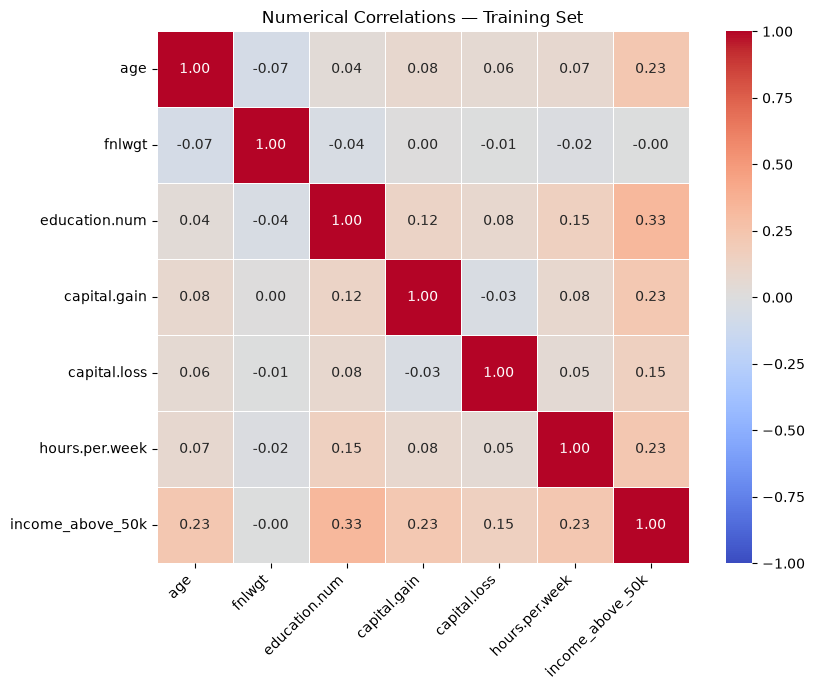

In [14]:
import seaborn as sns

# Select numerical inputs from the training set
correlation_data = X_train.select_dtypes(include="number").copy()

# Add the target for exploration only—not as a model input
correlation_data["income_above_50k"] = y_train

# Calculate Pearson correlation
correlation_matrix = correlation_data.corr(method="pearson")

# Draw a compact, readable heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Numerical Correlations — Training Set")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 11 — Finalise the Initial Feature Set

### Heatmap findings
Education level had the largest positive correlation with the
target among the numerical inputs, approximately 0.33.

Age, capital gain and weekly working hours each had correlations
of approximately 0.23. Capital loss had approximately 0.15.

These values describe individual straight-line associations,
not model accuracy or complete feature importance.

### Decision: exclude fnlwgt from the initial inputs
fnlwgt is a census sampling weight. It indicates how many people
in the population a record represents.

Our initial model will predict the income category of an individual
record using their attributes, so we will exclude this sampling
metadata from the predictors.

We are not removing it solely because its correlation is near zero.

### Alternative and limitation
We could test including fnlwgt as a predictor using validation data.

We could also use census weights as sample weights for a
population-oriented analysis. That is a different decision from
using them as a predictor.

Our initial training and evaluation will be unweighted:
each record contributes equally. Therefore, reported results
describe performance across dataset records, rather than
census-weighted population performance.

### Assessment explanation
“We excluded the census sampling weight from our initial predictors
because it describes population representation. We did not treat
near-zero correlation as proof that a feature has no predictive value.”

In [15]:
# Remove census sampling metadata from the initial model inputs
# Keep the source df unchanged so the weights remain available
X_train = X_train.drop(columns=["fnlwgt"])
X_val = X_val.drop(columns=["fnlwgt"])
X_test = X_test.drop(columns=["fnlwgt"])

# Verify consistent inputs
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)
print("Test input shape:", X_test.shape)

Training input shape: (22775, 12)
Validation input shape: (4881, 12)
Test input shape: (4881, 12)


## Step 12 — Handle Missing Categorical Values

### Decision
Replace missing categorical values with the label "Unknown".

Apply this rule consistently to training, validation and test inputs.

### Why?
This preserves the other useful information in each record without
guessing someone's occupation, employment category or country.

Later, one-hot encoding will convert these categories into numerical
inputs the neural network can use.

### Alternative and trade-off
We could fill missing values with the most frequent category
learned from training data.

However, that would assign an occupation or country without
evidence. Using "Unknown" explicitly preserves the missingness.

The trade-off is that the model may learn patterns associated
with missing information. Those patterns may change in future data.

### Why is applying this to all sets acceptable?
"Unknown" is a fixed replacement rule. It does not calculate
statistics or learn anything from validation or test data.

Our encoder and scaler will still be fitted on training data only.

### Assessment explanation
“We preserved records by replacing missing categorical values
with an explicit Unknown category. This avoided inventing personal
attributes or discarding otherwise useful records.”

In [16]:
# Identify numerical and categorical columns from training inputs
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()

categorical_columns = [
    column for column in X_train.columns
    if column not in numeric_columns
]

print("Numerical columns:", numeric_columns)
print("\nCategorical columns:", categorical_columns)

# Use the same fixed replacement rule for all three sets
missing_replacements = {
    column: "Unknown"
    for column in categorical_columns
}

X_train = X_train.fillna(missing_replacements)
X_val = X_val.fillna(missing_replacements)
X_test = X_test.fillna(missing_replacements)

# Verify that no missing inputs remain
print("\nRemaining missing values:")
print("Training:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

Numerical columns: ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

Categorical columns: ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']

Remaining missing values:
Training: 0
Validation: 0
Test: 0


## Step 13 — Encode Categories and Scale Numerical Features

### Decision 1: One-hot encode categorical features
Create a separate 0/1 input for each category.

Why?
Categories such as occupations have no natural numerical order.
Assigning arbitrary numbers could introduce misleading distances.

Alternative:
Learned embeddings can provide compact representations, but
one-hot encoding is a clear starting choice for this dataset.

Trade-off:
One categorical column becomes several numerical columns.

### Decision 2: Standardise numerical features
Use StandardScaler to subtract each feature's training mean
and divide by its training standard deviation.

Why?
Age, working hours and capital gains have very different scales.
Standardisation often helps neural network optimisation.

Training numerical features will have approximately mean 0
and standard deviation 1. Values are not restricted to 0–1.

Alternative:
Min-max scaling uses a bounded training range, but extreme values
can compress most observations into a small part of that range.

Limitation:
StandardScaler is also sensitive to extreme values and does not
remove skewness. We use it as an initial choice.

### Prevent data leakage
Fit the preprocessing rules on training inputs only.
Apply those same rules to validation and test inputs.

Fit means learning the training means, standard deviations
and category vocabulary.

Transform means applying those already-learned rules.

### Unseen categories
Use handle_unknown="ignore" so a category absent from training
does not cause an error later. It becomes all zeros within that
feature's one-hot columns.

This differs from the explicit "Unknown" label used for missing values.

### Assessment explanation
“We used one-hot encoding to avoid imposing arbitrary order on
categories, and standardisation to put numerical inputs on comparable
scales. We fitted preprocessing only on training data to avoid leakage.”

In [17]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define preparation rules for the two types of input
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32
            ),
            categorical_columns
        )
    ]
)

# Learn preparation rules from training data only
X_train_processed = preprocessor.fit_transform(X_train).astype("float32")

# Apply the learned rules to validation and test data
X_val_processed = preprocessor.transform(X_val).astype("float32")
X_test_processed = preprocessor.transform(X_test).astype("float32")

# Check the resulting shapes
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

# Verify all processed values are valid numbers
for name, values in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed)
]:
    print(f"{name}: all values finite = {np.isfinite(values).all()}")

Training: (22775, 90)
Validation: (4881, 90)
Test: (4881, 90)
Training: all values finite = True
Validation: all values finite = True
Test: all values finite = True


## Step 14 — Check the Deep Learning Environment

### What we will use
- TensorFlow/Keras: build and train neural networks.
- MLflow: record experiment settings, metrics and model artifacts.
- scikit-learn: preprocessing and evaluation.

### Why check the environment first?
The notebook runs inside a selected Python kernel.
Packages installed in a different environment may not be available
to that kernel.

Recording package versions also helps explain and reproduce results.

### Model architecture decision
We will use multilayer perceptrons (MLPs).

Why?
Each record is a fixed collection of tabular attributes.
An MLP can combine these inputs and learn nonlinear relationships.

CNNs are designed around local structure, such as neighbouring pixels.
RNNs, LSTMs and GRUs are designed for sequences, where order matters.
Our census columns have neither image structure nor a time sequence.

We will compare at least three MLP configurations and track their
experiments in MLflow. We will define their differences before training.

### Assessment explanation
“We chose MLPs because the dataset contains fixed tabular features.
We checked the notebook environment and recorded package versions
to support reproducibility.”

In [18]:
import sys
from importlib import metadata, util

# Identify the Python environment used by this notebook
print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)

# Check packages without installing or changing anything
packages = [
    ("tensorflow", "tensorflow"),
    ("mlflow", "mlflow"),
    ("sklearn", "scikit-learn"),
    ("numpy", "numpy"),
    ("pandas", "pandas")
]

print("\nPackage availability:")

for module_name, package_name in packages:
    if util.find_spec(module_name) is None:
        print(f"{package_name}: NOT INSTALLED")
    else:
        try:
            version = metadata.version(package_name)
        except metadata.PackageNotFoundError:
            version = "version metadata unavailable"

        print(f"{package_name}: {version}")

Python version: 3.13.15
Python executable: c:\Saraswathi-DS\ds-october-2026-week2\.venv\Scripts\python.exe

Package availability:
tensorflow: 2.21.0
mlflow: 3.17.1
scikit-learn: 1.9.1
numpy: 2.5.4
pandas: 3.0.6


In [19]:
import tensorflow as tf
import mlflow

print("TensorFlow version:", tf.__version__)
print("MLflow version:", mlflow.__version__)

# Verify that TensorFlow can perform a basic calculation
result = tf.reduce_sum(tf.constant([1.0, 2.0, 3.0]))

print("TensorFlow calculation:", result.numpy())

TensorFlow version: 2.21.0
MLflow version: 3.17.1
TensorFlow calculation: 6.0


## Step 16 — Set Up Reproducibility and MLflow

### Decision 1: Control randomness
Neural networks start with random weights and usually shuffle
training examples.

Use a fixed random seed and deterministic TensorFlow operations
to help reproduce experiments in the same environment.

The seed 42 has no special performance advantage.
Exact results are not guaranteed across different hardware or
software versions. Deterministic operations can also be slower.

We will reset the seed before building each model.

### Decision 2: Track experiments locally
Create an MLflow experiment named Adult_Income_Deep_Learning.

An experiment groups related runs.
A run represents one training attempt.

We will record:
- Parameters: architecture, optimiser, learning rate and batch size.
- Metrics: loss, accuracy, precision, recall, F1 and other scores.
- Artifacts: charts, preprocessing objects and model files.

### Why SQLite?
SQLite stores experiment metadata in a local database file.
It is suitable for this individual assessment without requiring
a separate database service.

Larger shared projects may use a central MLflow server instead.

### Assessment explanation
“We controlled randomness to improve reproducibility and used MLflow
to preserve the settings and evidence for each experiment, allowing
us to compare models systematically.”

In [20]:
from pathlib import Path

# Control randomness before creating any models
SEED = 42

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

# Store tracking files relative to the notebook's working folder
PROJECT_DIR = Path.cwd().resolve()
database_path = PROJECT_DIR / "mlflow.db"
artifact_directory = PROJECT_DIR / "mlflow_artifacts"

artifact_directory.mkdir(exist_ok=True)

# Tell MLflow where to store experiment metadata
TRACKING_URI = f"sqlite:///{database_path.as_posix()}"
mlflow.set_tracking_uri(TRACKING_URI)

# Create the experiment once, or reuse it on later executions
EXPERIMENT_NAME = "Adult_Income_Deep_Learning"

experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

if experiment is None:
    mlflow.create_experiment(
        name=EXPERIMENT_NAME,
        artifact_location=artifact_directory.as_uri()
    )

mlflow.set_experiment(EXPERIMENT_NAME)

print("Random seed:", SEED)
print("Project directory:", PROJECT_DIR)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", EXPERIMENT_NAME)
print("Neural network input features:", X_train_processed.shape[1])

2026/10/15 20:47:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/15 20:47:16 INFO mlflow.store.db.utils: Updating database tables


Random seed: 42
Project directory: C:\Saraswathi-DS\ds-october-2026-week2
Tracking URI: sqlite:///C:/Saraswathi-DS/ds-october-2026-week2/mlflow.db
Experiment: Adult_Income_Deep_Learning
Neural network input features: 90


## Step 17 — Define Three Neural Network Configurations

### What is a hidden layer?
Imagine a team analysing each person's census record.

The input layer receives the 90 prepared values.
Hidden layers combine those values into learned patterns.
The output layer produces an estimated probability of income >$50K.

A neuron calculates a weighted sum of its inputs, adds a bias,
then applies an activation function.

Weights and biases are learned during training.
We choose the number of layers and neurons before training.

### Our three configurations

| Model | Hidden layers | Dropout |
|---|---|---|
| Small MLP | 32 → 16 | None |
| Larger MLP | 64 → 32 → 16 | None |
| Larger MLP with dropout | 64 → 32 → 16 | 0.2 after the first two hidden layers |

All three have:
- 90 input features.
- ReLU activation in hidden layers.
- One sigmoid output neuron.

### Why these configurations?
Small MLP:
A relatively compact starting model. It may generalise well,
but could lack capacity to learn more complex patterns.

Larger MLP:
Tests whether additional neurons and depth improve validation
performance. More capacity can also increase overfitting.

Larger MLP with dropout:
Uses the same hidden-layer sizes as the larger MLP, but randomly
sets some hidden activations to zero during training.

Dropout may reduce reliance on particular neurons and improve
generalisation, but can also cause underfitting.
Dropout is disabled during prediction.

### Why these exact sizes and dropout rate?
They are manageable starting choices, not mathematically optimal values.
Validation results will tell us whether they are useful.

### Why ReLU?
ReLU returns zero for negative inputs and leaves positive inputs
unchanged. It introduces nonlinearity, allowing the network
to learn more than a straight-line relationship.

### Why one sigmoid output?
Our target has two classes. Sigmoid gives a value between 0 and 1
that we interpret as an estimated probability of class 1.

We initially classify values >=0.5 as income >$50K.

### Shared starting training settings
- Optimiser: Adam
- Learning rate: 0.001
- Loss: binary cross-entropy
- Batch size: 64

Adam is a practical starting optimiser; we have not established
that it is the best for this dataset.

Binary cross-entropy suits a binary target with a sigmoid output.
It penalises incorrect probability estimates, especially confident
wrong predictions.

Keeping these settings fixed makes architecture comparisons clearer.
We can later compare SGD with momentum and RMSprop in extra runs.

### Assessment explanation
“We compared a compact MLP, a larger MLP, and the larger architecture
with dropout. We kept initial training settings consistent to
understand whether additional capacity or regularisation helped.”

In [21]:
model_configs = [
    {
        "name": "small_mlp",
        "hidden_units": [32, 16],
        "dropout_rate": 0.0
    },
    {
        "name": "larger_mlp",
        "hidden_units": [64, 32, 16],
        "dropout_rate": 0.0
    },
    {
        "name": "larger_mlp_dropout",
        "hidden_units": [64, 32, 16],
        "dropout_rate": 0.2
    }
]

LEARNING_RATE = 0.001
BATCH_SIZE = 64

for config in model_configs:
    print(
        f"{config['name']}: "
        f"hidden layers={config['hidden_units']}, "
        f"dropout={config['dropout_rate']}"
    )

print("\nShared optimiser: Adam")
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)

small_mlp: hidden layers=[32, 16], dropout=0.0
larger_mlp: hidden layers=[64, 32, 16], dropout=0.0
larger_mlp_dropout: hidden layers=[64, 32, 16], dropout=0.2

Shared optimiser: Adam
Learning rate: 0.001
Batch size: 64


## Step 18 — Build and Inspect the First Neural Network

### How information moves through the model
Imagine a team reviewing a person's census record:

1. The model receives 90 prepared input values.
2. The first hidden layer combines them into 32 activations.
3. The second hidden layer combines those into 16 activations.
4. The output neuron produces an estimated probability of income >$50K.

This movement from inputs to output is called a forward pass.

Neurons do not receive predefined jobs such as “check education”.
Their patterns are learned during training.

### What does each neuron calculate?
First:
weighted sum = input × weight + input × weight + ... + bias

Then:
activation = activation_function(weighted sum)

Weights control how inputs contribute.
The bias adjusts the neuron's weighted sum.
The activation function introduces nonlinearity.

### What does Dense mean?
Every neuron connects to every output from the previous layer.

### Count the trainable parameters
Each connection has one weight.
Each neuron in a Dense layer has one bias.

First hidden layer:
(90 inputs × 32 neurons) + 32 biases = 2,912

Second hidden layer:
(32 inputs × 16 neurons) + 16 biases = 528

Output layer:
(16 inputs × 1 neuron) + 1 bias = 17

Total:
2,912 + 528 + 17 = 3,457 trainable parameters.

### Why inspect the summary?
It verifies the architecture and parameter count before training.
More parameters provide more capacity, but do not guarantee
better validation performance.

### What does compile do?
It configures the optimiser, loss function and reported metrics.
It does not train the model.

We will calculate precision, recall and F1 from predictions later.

### Assessment explanation
“Our first MLP has two hidden layers with 32 and 16 neurons,
ReLU activations, and one sigmoid output. Its 3,457 trainable
parameters are the weights and biases adjusted during training.”

In [22]:
from tensorflow import keras
from tensorflow.keras import layers

# Reset randomness before building this model
keras.utils.set_random_seed(SEED)

# Build the small MLP
small_model = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_processed.shape[1],),
            name="census_inputs"
        ),
        layers.Dense(32, activation="relu", name="hidden_1"),
        layers.Dense(16, activation="relu", name="hidden_2"),
        layers.Dense(1, activation="sigmoid", name="income_probability")
    ],
    name="small_mlp"
)

# Configure how the model will learn
small_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy")
    ]
)

# Inspect layers, output shapes and parameter counts
small_model.summary()

Model: "small_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │         2,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ income_probability (Dense)      │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

## Step 19 — Train the Small MLP and Track It in MLflow

### What happens during training?
For each batch of records:

1. Forward pass: produce income probabilities.
2. Calculate loss: compare probabilities with actual income labels.
3. Backpropagation: calculate how weights and biases affect the loss.
4. Optimiser update: adjust weights and biases to reduce the loss.

The optimiser repeats this process across the training data.

### Batch size and epochs
Batch size 64 means approximately 64 records per training update.
The final batch may contain fewer records.

One epoch is one complete pass through the training records.

We choose a maximum of 50 epochs as an initial training budget,
not because 50 is known to be optimal.

### Why early stopping?
Training longer can improve training performance while making
validation performance worse.

Stop if validation loss does not improve for five consecutive epochs.
Restore the weights from the epoch with the lowest validation loss.

Patience of five gives the model some room for temporary fluctuations.
It is a starting choice that we will apply consistently to all models.

### Why monitor validation loss?
Binary cross-entropy evaluates the predicted probabilities and provides
a useful training signal without depending on a classification threshold.

We use validation loss to select the training checkpoint.
We will use validation F1 to compare the resulting models.

These are two distinct decisions.

### Does the model learn from validation records?
Validation records are not used for gradient updates.
However, they influence early stopping and model selection, so they
are not an independent final evaluation.

The test set remains reserved for the final selected model.

### MLflow tracking
Record training settings and loss/accuracy after every epoch.

### Assessment explanation
“We trained in batches with Adam and used early stopping to limit
overfitting. We restored the checkpoint with the lowest validation
loss and will compare models using validation F1.”

In [23]:
MAX_EPOCHS = 50
PATIENCE = 5

# Stop when validation loss stops improving
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

# Record metrics in the active MLflow run after each epoch
class MLflowEpochLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        metrics = {
            name: float(value)
            for name, value in (logs or {}).items()
            if value is not None
        }
        mlflow.log_metrics(metrics, step=epoch + 1)

# Fix randomness before training
keras.utils.set_random_seed(SEED)

with mlflow.start_run(run_name="small_mlp_adam") as run:
    small_run_id = run.info.run_id

    mlflow.log_params({
        "architecture": "90-32-16-1",
        "hidden_activation": "relu",
        "output_activation": "sigmoid",
        "dropout_rate": 0.0,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "checkpoint_monitor": "val_loss",
        "loss_function": "binary_crossentropy",
        "seed": SEED,
        "class_weighting": "none"
    })

    small_history = small_model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(
            X_val_processed,
            y_val.to_numpy()
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[early_stopping, MLflowEpochLogger()],
        verbose=2
    )

    best_epoch = int(np.argmin(small_history.history["val_loss"])) + 1

    mlflow.log_params({
        "epochs_completed": len(small_history.history["loss"]),
        "best_validation_loss_epoch": best_epoch
    })

    mlflow.log_dict(
        {
            key: [float(value) for value in values]
            for key, values in small_history.history.items()
        },
        "training_history.json"
    )

print("\nMLflow run ID:", small_run_id)
print("Best validation-loss epoch:", best_epoch)

Epoch 1/50
356/356 - 2s - 5ms/step - accuracy: 0.8290 - loss: 0.3665 - val_accuracy: 0.8519 - val_loss: 0.3226
Epoch 2/50
356/356 - 1s - 2ms/step - accuracy: 0.8532 - loss: 0.3099 - val_accuracy: 0.8539 - val_loss: 0.3188
Epoch 3/50
356/356 - 1s - 2ms/step - accuracy: 0.8564 - loss: 0.3047 - val_accuracy: 0.8506 - val_loss: 0.3183
Epoch 4/50
356/356 - 0s - 1ms/step - accuracy: 0.8589 - loss: 0.3019 - val_accuracy: 0.8498 - val_loss: 0.3180
Epoch 5/50
356/356 - 1s - 2ms/step - accuracy: 0.8600 - loss: 0.3000 - val_accuracy: 0.8504 - val_loss: 0.3179
Epoch 6/50
356/356 - 0s - 1ms/step - accuracy: 0.8605 - loss: 0.2984 - val_accuracy: 0.8494 - val_loss: 0.3180
Epoch 7/50
356/356 - 0s - 1ms/step - accuracy: 0.8616 - loss: 0.2970 - val_accuracy: 0.8484 - val_loss: 0.3182
Epoch 8/50
356/356 - 0s - 1ms/step - accuracy: 0.8621 - loss: 0.2958 - val_accuracy: 0.8490 - val_loss: 0.3185
Epoch 9/50
356/356 - 0s - 1ms/step - accuracy: 0.8628 - loss: 0.2946 - val_accuracy: 0.8498 - val_loss: 0.3190
E

## Step 20 — Evaluate the Restored Small MLP

### Training findings
Training stopped after 10 epochs.
The lowest validation loss occurred at epoch 5.
Early stopping restored the weights from that epoch.

Training loss continued decreasing while validation loss increased
slightly after epoch 5, suggesting the beginning of overfitting.

### What we will do
Use the restored model to predict validation probabilities.
Convert probabilities into classes using our fixed threshold of 0.5.

Compare predictions against the actual validation labels.

### Metrics
- Accuracy: proportion of all predictions that are correct.
- Precision: correct higher-income predictions divided by all
  predicted higher-income records.
- Recall: correctly identified higher-income records divided by
  all actual higher-income records.
- F1: combines higher-income precision and recall.
- ROC-AUC: evaluates how well probability scores rank the classes.
- Average precision: summarises the precision-recall curve.

ROC-AUC and average precision use probabilities, not the
thresholded predictions.

### Why evaluate again?
The model contains restored epoch 5 weights, while the final
training log describes epoch 10.

We will record these checkpoint evaluation metrics separately
in the same MLflow run.

### Assessment explanation
“We evaluated the restored checkpoint on validation records using
a consistent threshold. We reported several metrics because accuracy
alone could hide poor detection of higher-income people.”

,Score
validation_accuracy,0.8504
validation_precision,0.7221
validation_recall,0.6165
validation_f1,0.6651
validation_roc_auc,0.9075
validation_average_precision,0.7747


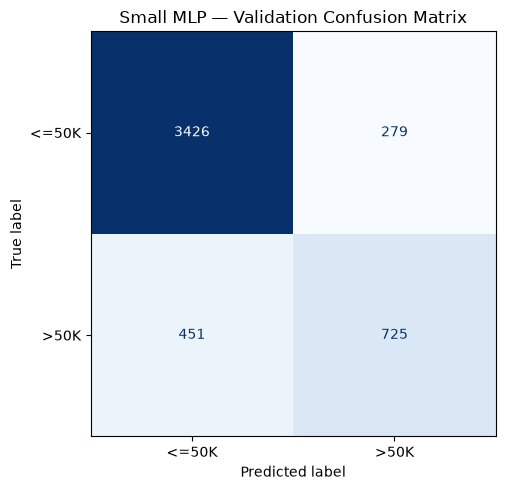

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

THRESHOLD = 0.5

# Predict using the restored epoch 5 weights
small_val_probabilities = small_model.predict(
    X_val_processed,
    verbose=0
).ravel()

small_val_predictions = (
    small_val_probabilities >= THRESHOLD
).astype("int32")

# Evaluate against the known validation labels
small_val_metrics = {
    "validation_accuracy": accuracy_score(y_val, small_val_predictions),
    "validation_precision": precision_score(
        y_val, small_val_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, small_val_predictions, zero_division=0
    ),
    "validation_f1": f1_score(
        y_val, small_val_predictions, zero_division=0
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, small_val_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, small_val_probabilities
    )
}

display(
    pd.DataFrame(
        small_val_metrics,
        index=["Small MLP"]
    ).T.rename(columns={"Small MLP": "Score"}).round(4)
)

# Display actual versus predicted income categories
small_cm = confusion_matrix(
    y_val,
    small_val_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=small_cm,
    display_labels=["<=50K", ">50K"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Small MLP — Validation Confusion Matrix")
plt.tight_layout()

# Add evaluation evidence to the existing training run
with mlflow.start_run(run_id=small_run_id):
    mlflow.log_param("prediction_threshold", THRESHOLD)
    mlflow.log_metrics(small_val_metrics)
    mlflow.log_figure(fig, "validation_confusion_matrix.png")

plt.show()

## Step 20 — Small MLP Validation Findings

At a probability threshold of 0.5:

- Accuracy: 85.04%
- Higher-income precision: 72.21%
- Higher-income recall: 61.65%
- Higher-income F1: 0.6651
- ROC-AUC: 0.9075
- Average precision: 0.7747

Of 1,176 actual higher-income records:
- 725 were correctly identified.
- 451 were missed.

Of 1,004 predicted higher-income records:
- 725 were correct.
- 279 were incorrect.

### Interpretation
The model identifies useful patterns, but misses approximately
38% of higher-income records at the chosen threshold.

ROC-AUC describes ranking performance; it does not mean
90.75% classification accuracy.

### Decision
Keep these results as our first neural network reference.
Compare the other planned architectures using the same data,
preprocessing, threshold and evaluation metrics.

We have not yet established whether class weighting or a different
threshold improves the precision-recall trade-off.

## Step 21 — Inspect Learning Curves

### What we will plot
Training and validation loss and accuracy across epochs.

### Why?
Learning curves help distinguish continued learning from overfitting.

If training loss falls while validation loss rises, the model may
be fitting training-specific patterns that do not generalise.

### Decision
Mark the epoch with the lowest validation loss.
The evaluated model uses the weights restored from this epoch.

The curves show the entire training history, including later epochs
whose weights were not retained.

### Assessment explanation
“We inspected learning curves to support our early-stopping decision
and understand whether additional training improved generalisation.”

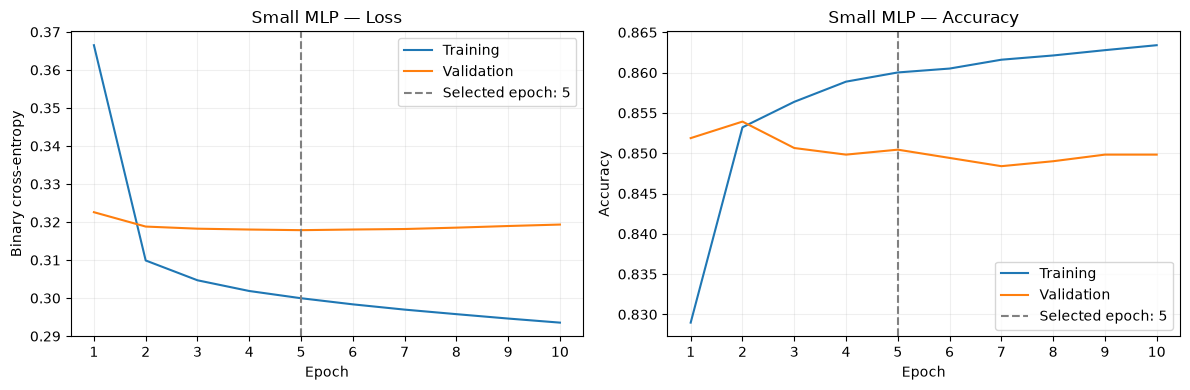

In [25]:
epochs = range(1, len(small_history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Probability prediction error
axes[0].plot(
    epochs, small_history.history["loss"], label="Training"
)
axes[0].plot(
    epochs, small_history.history["val_loss"], label="Validation"
)
axes[0].set_title("Small MLP — Loss")
axes[0].set_ylabel("Binary cross-entropy")

# Classification accuracy
axes[1].plot(
    epochs, small_history.history["accuracy"], label="Training"
)
axes[1].plot(
    epochs, small_history.history["val_accuracy"], label="Validation"
)
axes[1].set_title("Small MLP — Accuracy")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.axvline(
        best_epoch,
        color="grey",
        linestyle="--",
        label=f"Selected epoch: {best_epoch}"
    )
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()

# Save the chart to the same MLflow run
with mlflow.start_run(run_id=small_run_id):
    mlflow.log_figure(fig, "learning_curves.png")

plt.show()

## Step 22 — Train the Larger MLP

### Architecture
90 inputs → 64 → 32 → 16 hidden neurons → 1 output

This model has 8,449 trainable parameters, compared with
3,457 in the small MLP.

### Why test a larger network?
Additional neurons and depth provide more capacity to learn
combinations of census attributes.

However, more capacity does not guarantee better predictions.
It can also increase overfitting.

### What stays consistent?
- Training and validation records
- Preprocessing
- ReLU hidden activations and sigmoid output
- Adam optimiser and learning rate of 0.001
- Batch size of 64
- Maximum of 50 epochs
- Early stopping patience of 5
- No class weights or dropout

Each model starts with fresh weights and a fresh optimiser.
We reset the random seed before building and training.

### Comparison limitation
We change both network width and depth, so this experiment tests
the larger architecture as a whole. It cannot isolate which change
caused any improvement.

A single seed also cannot establish that small score differences
are reliable across repeated training runs.

### Assessment explanation
“We increased model capacity while keeping the initial training
procedure consistent. Validation results will determine whether
the extra complexity improves generalisation.”

In [26]:
# Build a fresh larger model
keras.utils.set_random_seed(SEED)

larger_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_processed.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ],
    name="larger_mlp"
)

larger_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")]
)

print("Trainable parameters:", larger_model.count_params())

# Use a fresh early-stopping callback for this model
larger_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

keras.utils.set_random_seed(SEED)

with mlflow.start_run(run_name="larger_mlp_adam") as run:
    larger_run_id = run.info.run_id

    mlflow.log_params({
        "architecture": "90-64-32-16-1",
        "trainable_parameters": larger_model.count_params(),
        "hidden_activation": "relu",
        "output_activation": "sigmoid",
        "dropout_rate": 0.0,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "checkpoint_monitor": "val_loss",
        "loss_function": "binary_crossentropy",
        "seed": SEED,
        "class_weighting": "none"
    })

    larger_history = larger_model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(X_val_processed, y_val.to_numpy()),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[larger_early_stopping, MLflowEpochLogger()],
        verbose=2
    )

    larger_best_epoch = (
        int(np.argmin(larger_history.history["val_loss"])) + 1
    )

    mlflow.log_params({
        "epochs_completed": len(larger_history.history["loss"]),
        "best_validation_loss_epoch": larger_best_epoch
    })

    mlflow.log_dict(
        {
            key: [float(value) for value in values]
            for key, values in larger_history.history.items()
        },
        "training_history.json"
    )

print("\nMLflow run ID:", larger_run_id)
print("Best validation-loss epoch:", larger_best_epoch)

Trainable parameters: 8449
Epoch 1/50
356/356 - 1s - 4ms/step - accuracy: 0.8283 - loss: 0.3550 - val_accuracy: 0.8515 - val_loss: 0.3186
Epoch 2/50
356/356 - 1s - 2ms/step - accuracy: 0.8566 - loss: 0.3057 - val_accuracy: 0.8511 - val_loss: 0.3177
Epoch 3/50
356/356 - 1s - 2ms/step - accuracy: 0.8588 - loss: 0.3014 - val_accuracy: 0.8500 - val_loss: 0.3177
Epoch 4/50
356/356 - 1s - 1ms/step - accuracy: 0.8604 - loss: 0.2984 - val_accuracy: 0.8509 - val_loss: 0.3183
Epoch 5/50
356/356 - 1s - 1ms/step - accuracy: 0.8619 - loss: 0.2959 - val_accuracy: 0.8509 - val_loss: 0.3186
Epoch 6/50
356/356 - 1s - 1ms/step - accuracy: 0.8626 - loss: 0.2934 - val_accuracy: 0.8515 - val_loss: 0.3197
Epoch 7/50
356/356 - 1s - 2ms/step - accuracy: 0.8638 - loss: 0.2910 - val_accuracy: 0.8509 - val_loss: 0.3211
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.

MLflow run ID: 1d78e5d48c4845329c9d0fe1fb1e7086
Best validation-loss epoch: 2


## Step 23 — Evaluate the Larger MLP

### Training findings
- Trainable parameters: 8,449
- Epochs completed: 7
- Selected checkpoint: epoch 2
- Lowest validation loss: approximately 0.3177

Training loss continued falling, but validation loss increased
after the selected checkpoint.

### Interpretation
The larger network fitted the training data more closely,
but has not yet demonstrated better generalisation.

Its minimum validation loss was very similar to the small MLP's.
More parameters did not produce a clear improvement in this measure.

### Evaluation decision
Evaluate the restored checkpoint using the same validation records,
probability threshold and metrics as the small MLP.

Compare validation F1 alongside precision, recall and ranking metrics.
Do not select a model using its training accuracy.

### Assessment explanation
“The larger network began overfitting earlier and achieved a similar
validation loss. We evaluated its restored checkpoint to determine
whether the additional complexity improved our primary metric, F1.”

,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision
Small MLP,0.8504,0.7221,0.6165,0.6651,0.9075,0.7747
Larger MLP,0.8511,0.7514,0.5706,0.6486,0.9081,0.7768


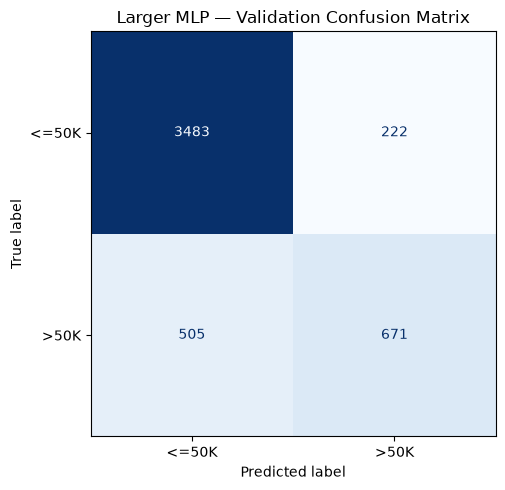

In [27]:
# Predict using the restored larger-model checkpoint
larger_val_probabilities = larger_model.predict(
    X_val_processed,
    verbose=0
).ravel()

larger_val_predictions = (
    larger_val_probabilities >= THRESHOLD
).astype("int32")

# Use the same metrics as the small model
larger_val_metrics = {
    "validation_accuracy": accuracy_score(y_val, larger_val_predictions),
    "validation_precision": precision_score(
        y_val, larger_val_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, larger_val_predictions, zero_division=0
    ),
    "validation_f1": f1_score(
        y_val, larger_val_predictions, zero_division=0
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, larger_val_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, larger_val_probabilities
    )
}

# Compare the two restored models
comparison_so_far = pd.DataFrame(
    [small_val_metrics, larger_val_metrics],
    index=["Small MLP", "Larger MLP"]
)

display(comparison_so_far.round(4))

# Show the larger model's errors
larger_cm = confusion_matrix(
    y_val, larger_val_predictions, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=larger_cm,
    display_labels=["<=50K", ">50K"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Larger MLP — Validation Confusion Matrix")
plt.tight_layout()

# Record checkpoint evaluation in its existing MLflow run
with mlflow.start_run(run_id=larger_run_id):
    mlflow.log_param("prediction_threshold", THRESHOLD)
    mlflow.log_metrics(larger_val_metrics)
    mlflow.log_figure(fig, "validation_confusion_matrix.png")

plt.show()

## Step 24 — Train the Larger MLP with Dropout

### Previous comparison
The larger MLP increased precision but reduced recall.
Its validation F1 was 0.6486, compared with 0.6651 for the small MLP.

At our fixed threshold, additional model capacity did not improve
the primary selection metric in this run.

### Decision
Keep the larger architecture and add dropout of 0.2 after its
first two hidden layers.

Architecture:
90 → Dense(64) → Dropout(0.2) → Dense(32) → Dropout(0.2)
→ Dense(16) → Dense(1)

### Everyday example
Imagine a team that relies too heavily on a few members.
During practice, temporarily removing different members encourages
the team to work using other combinations.

Dropout similarly sets randomly selected activations to zero
during training.

### Why 0.2?
It is a moderate starting rate: each activation at those dropout
layers has a 20% chance of being set to zero during a training pass.

It is not an established optimum.

### Why test it?
Our larger model showed signs of overfitting.
Dropout may reduce reliance on training-specific patterns.

It may also reduce useful learning, so improvement is not guaranteed.
It does not directly correct class imbalance.

### What stays consistent?
Keep the Dense layer sizes, optimiser, learning rate, batch size,
data splits and early-stopping procedure unchanged.

Dropout adds no trainable parameters.
The model still has 8,449 trainable parameters.

Dropout is disabled during validation and prediction.

### Assessment explanation
“We tested dropout because the larger model showed overfitting.
We retained its architecture and training settings to investigate
whether regularisation improved validation performance.”

In [28]:
# Build a fresh model with dropout
keras.utils.set_random_seed(SEED)

dropout_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_processed.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ],
    name="larger_mlp_dropout"
)

dropout_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")]
)

print("Trainable parameters:", dropout_model.count_params())

dropout_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

keras.utils.set_random_seed(SEED)

with mlflow.start_run(run_name="larger_mlp_dropout_adam") as run:
    dropout_run_id = run.info.run_id

    mlflow.log_params({
        "architecture": "90-64-32-16-1",
        "trainable_parameters": dropout_model.count_params(),
        "hidden_activation": "relu",
        "output_activation": "sigmoid",
        "dropout_rate": 0.2,
        "dropout_after_hidden_layers": "1,2",
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "checkpoint_monitor": "val_loss",
        "loss_function": "binary_crossentropy",
        "seed": SEED,
        "class_weighting": "none"
    })

    dropout_history = dropout_model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(X_val_processed, y_val.to_numpy()),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[dropout_early_stopping, MLflowEpochLogger()],
        verbose=2
    )

    dropout_best_epoch = (
        int(np.argmin(dropout_history.history["val_loss"])) + 1
    )

    mlflow.log_params({
        "epochs_completed": len(dropout_history.history["loss"]),
        "best_validation_loss_epoch": dropout_best_epoch
    })

    mlflow.log_dict(
        {
            key: [float(value) for value in values]
            for key, values in dropout_history.history.items()
        },
        "training_history.json"
    )

print("\nMLflow run ID:", dropout_run_id)
print("Best validation-loss epoch:", dropout_best_epoch)

Trainable parameters: 8449
Epoch 1/50
356/356 - 1s - 4ms/step - accuracy: 0.8170 - loss: 0.3821 - val_accuracy: 0.8474 - val_loss: 0.3189
Epoch 2/50
356/356 - 1s - 2ms/step - accuracy: 0.8496 - loss: 0.3205 - val_accuracy: 0.8498 - val_loss: 0.3159
Epoch 3/50
356/356 - 1s - 2ms/step - accuracy: 0.8551 - loss: 0.3129 - val_accuracy: 0.8504 - val_loss: 0.3155
Epoch 4/50
356/356 - 1s - 2ms/step - accuracy: 0.8569 - loss: 0.3082 - val_accuracy: 0.8488 - val_loss: 0.3151
Epoch 5/50
356/356 - 1s - 2ms/step - accuracy: 0.8607 - loss: 0.3052 - val_accuracy: 0.8486 - val_loss: 0.3146
Epoch 6/50
356/356 - 1s - 2ms/step - accuracy: 0.8605 - loss: 0.3020 - val_accuracy: 0.8500 - val_loss: 0.3149
Epoch 7/50
356/356 - 1s - 2ms/step - accuracy: 0.8605 - loss: 0.3007 - val_accuracy: 0.8502 - val_loss: 0.3142
Epoch 8/50
356/356 - 1s - 2ms/step - accuracy: 0.8613 - loss: 0.3001 - val_accuracy: 0.8502 - val_loss: 0.3159
Epoch 9/50
356/356 - 1s - 2ms/step - accuracy: 0.8627 - loss: 0.2976 - val_accuracy: 

## Step 25 — Evaluate the Dropout MLP and Compare All Three Models

### Training findings
The dropout model trained for 12 epochs.
Its lowest validation loss occurred at epoch 7.
Early stopping restored that checkpoint.

Its minimum validation loss was lower than the other two models.

### Interpretation
Dropout appears to have helped generalisation in terms of
validation cross-entropy in this run.

However, a lower probability-based loss does not guarantee
better F1 at our fixed classification threshold of 0.5.

### Decision
Evaluate the restored model using exactly the same validation
records, threshold and metrics as the previous models.

Rank models by validation F1, then inspect precision, recall
and other metrics to understand the trade-offs.

These are single-seed results. They do not establish that small
differences would persist across repeated training runs.

### Assessment explanation
“The dropout model achieved the lowest validation loss, but we
evaluated its F1 before choosing a winner. This kept model selection
consistent with our predefined evaluation criterion.”

,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision
Small MLP,0.8504,0.7221,0.6165,0.6651,0.9075,0.7747
Larger MLP with dropout,0.8502,0.7395,0.5842,0.6527,0.9095,0.7808
Larger MLP,0.8511,0.7514,0.5706,0.6486,0.9081,0.7768


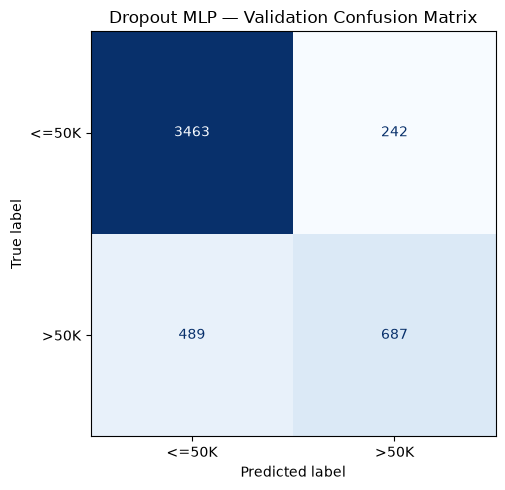

In [29]:
# Predict using the restored dropout-model checkpoint
dropout_val_probabilities = dropout_model.predict(
    X_val_processed,
    verbose=0
).ravel()

dropout_val_predictions = (
    dropout_val_probabilities >= THRESHOLD
).astype("int32")

# Calculate the same validation metrics
dropout_val_metrics = {
    "validation_accuracy": accuracy_score(y_val, dropout_val_predictions),
    "validation_precision": precision_score(
        y_val, dropout_val_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, dropout_val_predictions, zero_division=0
    ),
    "validation_f1": f1_score(
        y_val, dropout_val_predictions, zero_division=0
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, dropout_val_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, dropout_val_probabilities
    )
}

# Rank all three models using unrounded F1 scores
model_comparison = pd.DataFrame(
    [small_val_metrics, larger_val_metrics, dropout_val_metrics],
    index=["Small MLP", "Larger MLP", "Larger MLP with dropout"]
).sort_values("validation_f1", ascending=False)

display(model_comparison.round(4))

# Inspect the dropout model's error counts
dropout_cm = confusion_matrix(
    y_val, dropout_val_predictions, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=dropout_cm,
    display_labels=["<=50K", ">50K"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Dropout MLP — Validation Confusion Matrix")
plt.tight_layout()

# Add checkpoint evaluation to its existing MLflow run
with mlflow.start_run(run_id=dropout_run_id):
    mlflow.log_param("prediction_threshold", THRESHOLD)
    mlflow.log_metrics(dropout_val_metrics)
    mlflow.log_figure(fig, "validation_confusion_matrix.png")

plt.show()

## Step 26 — Test SGD with Momentum

### Architecture decision
Use the leading small MLP: 90 → 32 → 16 → 1.

Keeping the architecture fixed helps us investigate training settings
without also changing network capacity.

### What does an optimiser do?
Backpropagation calculates gradients: how changes to weights and
biases affect the loss.

The optimiser uses those gradients to update the parameters.

### Everyday example
Imagine walking downhill:
- Gradient: indicates the local uphill direction.
- Learning rate: controls the size of the step downhill.
- Momentum: carries some movement from previous steps forward.

### Why SGD with momentum?
Mini-batch SGD updates parameters using the current batch's gradient.
Momentum combines this with previous movement, which can help
reduce zigzagging and maintain progress.

Adam adapts updates using moving estimates of gradients and
squared gradients. SGD with momentum provides a useful alternative.

### Starting settings
- Learning rate: 0.01
- Momentum: 0.9

The learning rate controls update size.
Momentum 0.9 retains 90% of the previous velocity in its update rule;
it does not mean 90% accuracy.

These are starting choices, not proven optimal settings.

### Comparison limitation
We are comparing configured optimiser setups:
Adam at 0.001 versus SGD with momentum at 0.01.

Different optimisers may need different learning rates.
This experiment cannot establish that one optimiser is universally
better. Both use the same maximum training budget and stopping rule.

### Assessment explanation
“We tested SGD with momentum on the leading architecture.
We documented its learning rate and momentum because optimiser
performance depends on these settings.”

In [31]:
# Build a fresh small MLP with a different optimiser
keras.utils.set_random_seed(SEED)

sgd_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_processed.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ],
    name="small_mlp_sgd"
)

SGD_LEARNING_RATE = 0.01
MOMENTUM = 0.9

sgd_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=SGD_LEARNING_RATE,
        momentum=MOMENTUM
    ),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")]
)

sgd_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

keras.utils.set_random_seed(SEED)

with mlflow.start_run(run_name="small_mlp_sgd_momentum") as run:
    sgd_run_id = run.info.run_id

    mlflow.log_params({
        "architecture": "90-32-16-1",
        "trainable_parameters": sgd_model.count_params(),
        "hidden_activation": "relu",
        "output_activation": "sigmoid",
        "dropout_rate": 0.0,
        "optimizer": "SGD",
        "learning_rate": SGD_LEARNING_RATE,
        "momentum": MOMENTUM,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "checkpoint_monitor": "val_loss",
        "loss_function": "binary_crossentropy",
        "seed": SEED,
        "class_weighting": "none"
    })

    sgd_history = sgd_model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(X_val_processed, y_val.to_numpy()),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[sgd_early_stopping, MLflowEpochLogger()],
        verbose=2
    )

    sgd_best_epoch = int(np.argmin(sgd_history.history["val_loss"])) + 1

    mlflow.log_params({
        "epochs_completed": len(sgd_history.history["loss"]),
        "best_validation_loss_epoch": sgd_best_epoch
    })

    mlflow.log_dict(
        {
            key: [float(value) for value in values]
            for key, values in sgd_history.history.items()
        },
        "training_history.json"
    )

print("\nMLflow run ID:", sgd_run_id)
print("Best validation-loss epoch:", sgd_best_epoch)

Epoch 1/50
356/356 - 1s - 3ms/step - accuracy: 0.8281 - loss: 0.3640 - val_accuracy: 0.8474 - val_loss: 0.3251
Epoch 2/50
356/356 - 1s - 2ms/step - accuracy: 0.8513 - loss: 0.3141 - val_accuracy: 0.8504 - val_loss: 0.3218
Epoch 3/50
356/356 - 1s - 1ms/step - accuracy: 0.8537 - loss: 0.3094 - val_accuracy: 0.8494 - val_loss: 0.3214
Epoch 4/50
356/356 - 1s - 1ms/step - accuracy: 0.8551 - loss: 0.3073 - val_accuracy: 0.8488 - val_loss: 0.3212
Epoch 5/50
356/356 - 0s - 1ms/step - accuracy: 0.8567 - loss: 0.3058 - val_accuracy: 0.8492 - val_loss: 0.3211
Epoch 6/50
356/356 - 0s - 1ms/step - accuracy: 0.8575 - loss: 0.3048 - val_accuracy: 0.8496 - val_loss: 0.3213
Epoch 7/50
356/356 - 0s - 1ms/step - accuracy: 0.8579 - loss: 0.3038 - val_accuracy: 0.8496 - val_loss: 0.3214
Epoch 8/50
356/356 - 0s - 1ms/step - accuracy: 0.8586 - loss: 0.3031 - val_accuracy: 0.8509 - val_loss: 0.3215
Epoch 9/50
356/356 - 1s - 1ms/step - accuracy: 0.8590 - loss: 0.3024 - val_accuracy: 0.8492 - val_loss: 0.3211
E

## Step 27 — Evaluate SGD with Momentum

### Training findings
- Optimiser: SGD with momentum 0.9
- Learning rate: 0.01
- Epochs completed: 15
- Selected checkpoint: epoch 10
- Lowest validation loss: approximately 0.3210

The small MLP with Adam achieved a lower validation loss,
approximately 0.3179.

### Decision
Evaluate SGD's restored checkpoint using the same validation
records, threshold of 0.5 and metrics as the other models.

The learning rate and stopping rule affect this result.
We cannot conclude that SGD is generally worse than Adam
from one configuration and one random seed.

### Assessment explanation
“SGD with momentum achieved a higher validation loss than Adam
in our experiment. We also compared F1, precision and recall
before judging its classification performance.”

,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision
Small MLP — Adam,0.8504,0.7221,0.6165,0.6651,0.9075,0.7747
Larger MLP with dropout — Adam,0.8502,0.7395,0.5842,0.6527,0.9095,0.7808
Larger MLP — Adam,0.8511,0.7514,0.5706,0.6486,0.9081,0.7768
Small MLP — SGD with momentum,0.8494,0.7415,0.5757,0.6482,0.9066,0.7746


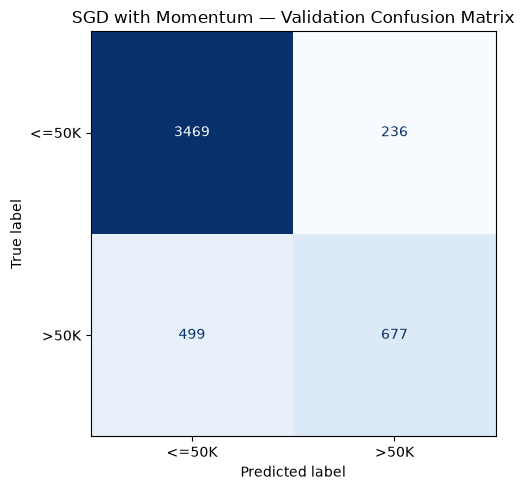

In [32]:
# Predict using SGD's restored checkpoint
sgd_val_probabilities = sgd_model.predict(
    X_val_processed,
    verbose=0
).ravel()

sgd_val_predictions = (
    sgd_val_probabilities >= THRESHOLD
).astype("int32")

sgd_val_metrics = {
    "validation_accuracy": accuracy_score(y_val, sgd_val_predictions),
    "validation_precision": precision_score(
        y_val, sgd_val_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, sgd_val_predictions, zero_division=0
    ),
    "validation_f1": f1_score(
        y_val, sgd_val_predictions, zero_division=0
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, sgd_val_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, sgd_val_probabilities
    )
}

# Compare all evaluated configurations
model_comparison = pd.DataFrame(
    [
        small_val_metrics,
        larger_val_metrics,
        dropout_val_metrics,
        sgd_val_metrics
    ],
    index=[
        "Small MLP — Adam",
        "Larger MLP — Adam",
        "Larger MLP with dropout — Adam",
        "Small MLP — SGD with momentum"
    ]
).sort_values("validation_f1", ascending=False)

display(model_comparison.round(4))

# Plot SGD's validation confusion matrix
sgd_cm = confusion_matrix(
    y_val, sgd_val_predictions, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=sgd_cm,
    display_labels=["<=50K", ">50K"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("SGD with Momentum — Validation Confusion Matrix")
plt.tight_layout()

# Save evaluation evidence to the SGD run
with mlflow.start_run(run_id=sgd_run_id):
    mlflow.log_param("prediction_threshold", THRESHOLD)
    mlflow.log_metrics(sgd_val_metrics)
    mlflow.log_figure(fig, "validation_confusion_matrix.png")

plt.show()

## Step 28 — Test RMSprop

### Previous finding
SGD with momentum achieved validation F1 of 0.6482.
The small MLP with Adam remains ahead at 0.6651.

### What does RMSprop do?
RMSprop keeps a moving average of squared gradients for each
parameter and uses it to scale that parameter's updates.

Parameters with consistently large gradients receive smaller
effective steps. This can help control uneven updates.

### Everyday example
Imagine walking downhill across uneven ground.
Instead of using the same step size everywhere, you adjust
your steps according to the conditions.

This is an analogy: RMSprop uses gradient history to scale updates.

### Decision
Use the same small MLP with:
- RMSprop optimiser
- Learning rate of 0.001
- rho of 0.9
- Momentum of 0.0

rho controls how much previous squared-gradient history is retained.
It is different from SGD's momentum.

These are starting settings, not proven optimal values.

### Why test it?
It provides another adaptive update method to compare with Adam
and SGD with momentum.

Keep the architecture, data, batch size and early-stopping rule
consistent with the previous experiments.

### Assessment explanation
“We tested RMSprop to compare another adaptive optimiser on the
same architecture. We selected between configured experiments
using validation evidence, rather than assuming an optimiser
would perform best.”

In [33]:
# Build a fresh small MLP
keras.utils.set_random_seed(SEED)

rmsprop_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_processed.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ],
    name="small_mlp_rmsprop"
)

RMSPROP_LEARNING_RATE = 0.001
RMSPROP_RHO = 0.9

rmsprop_model.compile(
    optimizer=keras.optimizers.RMSprop(
        learning_rate=RMSPROP_LEARNING_RATE,
        rho=RMSPROP_RHO,
        momentum=0.0
    ),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")]
)

rmsprop_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

keras.utils.set_random_seed(SEED)

with mlflow.start_run(run_name="small_mlp_rmsprop") as run:
    rmsprop_run_id = run.info.run_id

    mlflow.log_params({
        "architecture": "90-32-16-1",
        "trainable_parameters": rmsprop_model.count_params(),
        "hidden_activation": "relu",
        "output_activation": "sigmoid",
        "dropout_rate": 0.0,
        "optimizer": "RMSprop",
        "learning_rate": RMSPROP_LEARNING_RATE,
        "rho": RMSPROP_RHO,
        "momentum": 0.0,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "checkpoint_monitor": "val_loss",
        "loss_function": "binary_crossentropy",
        "seed": SEED,
        "class_weighting": "none"
    })

    rmsprop_history = rmsprop_model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(X_val_processed, y_val.to_numpy()),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[rmsprop_early_stopping, MLflowEpochLogger()],
        verbose=2
    )

    rmsprop_best_epoch = (
        int(np.argmin(rmsprop_history.history["val_loss"])) + 1
    )

    mlflow.log_params({
        "epochs_completed": len(rmsprop_history.history["loss"]),
        "best_validation_loss_epoch": rmsprop_best_epoch
    })

    mlflow.log_dict(
        {
            key: [float(value) for value in values]
            for key, values in rmsprop_history.history.items()
        },
        "training_history.json"
    )

print("\nMLflow run ID:", rmsprop_run_id)
print("Best validation-loss epoch:", rmsprop_best_epoch)

Epoch 1/50
356/356 - 1s - 3ms/step - accuracy: 0.8329 - loss: 0.3580 - val_accuracy: 0.8494 - val_loss: 0.3221
Epoch 2/50
356/356 - 1s - 2ms/step - accuracy: 0.8526 - loss: 0.3108 - val_accuracy: 0.8515 - val_loss: 0.3190
Epoch 3/50
356/356 - 1s - 2ms/step - accuracy: 0.8548 - loss: 0.3068 - val_accuracy: 0.8527 - val_loss: 0.3178
Epoch 4/50
356/356 - 1s - 2ms/step - accuracy: 0.8566 - loss: 0.3046 - val_accuracy: 0.8517 - val_loss: 0.3173
Epoch 5/50
356/356 - 1s - 1ms/step - accuracy: 0.8585 - loss: 0.3031 - val_accuracy: 0.8519 - val_loss: 0.3170
Epoch 6/50
356/356 - 0s - 1ms/step - accuracy: 0.8593 - loss: 0.3019 - val_accuracy: 0.8504 - val_loss: 0.3168
Epoch 7/50
356/356 - 0s - 1ms/step - accuracy: 0.8595 - loss: 0.3009 - val_accuracy: 0.8506 - val_loss: 0.3165
Epoch 8/50
356/356 - 0s - 1ms/step - accuracy: 0.8602 - loss: 0.3000 - val_accuracy: 0.8502 - val_loss: 0.3162
Epoch 9/50
356/356 - 0s - 1ms/step - accuracy: 0.8609 - loss: 0.2993 - val_accuracy: 0.8500 - val_loss: 0.3161
E

## Step 29 — Evaluate RMSprop and Compare Five Configurations

### Training findings
- Optimiser: RMSprop
- Learning rate: 0.001
- Epochs completed: 18
- Selected checkpoint: epoch 13
- Lowest validation loss: approximately 0.3161

### Why do several epochs show the same loss?
The displayed loss is rounded.
Early stopping compares the underlying values at greater precision,
so an improvement may occur even when the printed values look equal.

### Evaluation decision
Evaluate the restored epoch 13 checkpoint at threshold 0.5.

Compare all five configurations using validation F1, with precision,
recall and ranking metrics providing supporting evidence.

A lower validation loss does not automatically mean a higher F1.

### Assessment explanation
“RMSprop achieved a lower validation loss than Adam on the small
architecture. We evaluated its restored checkpoint using our
predefined classification metrics before judging the improvement.”

,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision
Small MLP — RMSprop,0.8509,0.7213,0.6207,0.6673,0.9083,0.7808
Small MLP — Adam,0.8504,0.7221,0.6165,0.6651,0.9075,0.7747
Larger MLP with dropout — Adam,0.8502,0.7395,0.5842,0.6527,0.9095,0.7808
Larger MLP — Adam,0.8511,0.7514,0.5706,0.6486,0.9081,0.7768
Small MLP — SGD with momentum,0.8494,0.7415,0.5757,0.6482,0.9066,0.7746


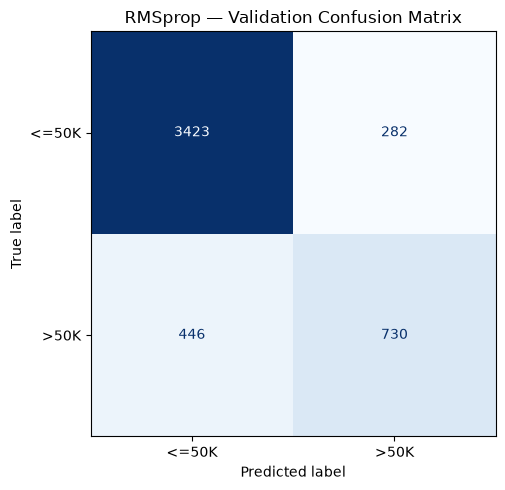

In [34]:
# Predict with the restored RMSprop checkpoint
rmsprop_val_probabilities = rmsprop_model.predict(
    X_val_processed,
    verbose=0
).ravel()

rmsprop_val_predictions = (
    rmsprop_val_probabilities >= THRESHOLD
).astype("int32")

rmsprop_val_metrics = {
    "validation_accuracy": accuracy_score(y_val, rmsprop_val_predictions),
    "validation_precision": precision_score(
        y_val, rmsprop_val_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, rmsprop_val_predictions, zero_division=0
    ),
    "validation_f1": f1_score(
        y_val, rmsprop_val_predictions, zero_division=0
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, rmsprop_val_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, rmsprop_val_probabilities
    )
}

# Compare all five configurations
model_comparison = pd.DataFrame(
    [
        small_val_metrics,
        larger_val_metrics,
        dropout_val_metrics,
        sgd_val_metrics,
        rmsprop_val_metrics
    ],
    index=[
        "Small MLP — Adam",
        "Larger MLP — Adam",
        "Larger MLP with dropout — Adam",
        "Small MLP — SGD with momentum",
        "Small MLP — RMSprop"
    ]
).sort_values("validation_f1", ascending=False)

display(model_comparison.round(4))

# Show RMSprop's error counts
rmsprop_cm = confusion_matrix(
    y_val, rmsprop_val_predictions, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=rmsprop_cm,
    display_labels=["<=50K", ">50K"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("RMSprop — Validation Confusion Matrix")
plt.tight_layout()

# Record evaluation in the existing RMSprop run
with mlflow.start_run(run_id=rmsprop_run_id):
    mlflow.log_param("prediction_threshold", THRESHOLD)
    mlflow.log_metrics(rmsprop_val_metrics)
    mlflow.log_figure(fig, "validation_confusion_matrix.png")

plt.show()

## Step 30 — Calculate Training Class Weights

### Current leading configuration
Small MLP with RMSprop:
- Validation F1: 0.6673
- Higher-income precision: 72.13%
- Higher-income recall: 62.07%
- Higher-income records missed: 446 out of 1,176

Its F1 advantage over Adam is small and has not been verified
across multiple random seeds.

### Decision
Test balanced class weights on the same small RMSprop architecture.

### Everyday example
Imagine marking practice answers.
Previously, each record contributed equally to the training loss.
Now, errors on the less common higher-income class receive
greater weight.

This changes the training objective without copying or deleting rows.

### How weights are calculated
For each class:

weight = total training records / (2 × records in that class)

The number 2 represents our two classes.

This gives each class equal total weight across the training set.
It does not make the record counts equal.

### Why use training counts only?
The weights are part of the learning procedure.
They must not be calculated from validation or test data.

### Expected trade-off
Class weighting may improve higher-income recall but increase
false alarms and reduce precision.

It may also change how well output probabilities reflect the
original class distribution.

Keep it only if validation evidence supports the change.

### Comparison rule
Continue using unweighted validation metrics at threshold 0.5.

Training loss will be weighted, while validation loss will remain
unweighted, so their levels are not directly comparable.

### Assessment explanation
“Our leading model still missed approximately 38% of higher-income
validation records. We therefore tested class weighting, calculated
from training counts only, and checked the resulting trade-off.”

In [35]:
# Calculate weights using training labels only
training_class_counts = (
    y_train.value_counts().reindex([0, 1])
)

class_weights = {
    int(label): float(
        len(y_train) / (2 * count)
    )
    for label, count in training_class_counts.items()
}

weight_summary = pd.DataFrame({
    "Income category": ["<=50K", ">50K"],
    "Training records": [
        training_class_counts[0],
        training_class_counts[1]
    ],
    "Class weight": [
        class_weights[0],
        class_weights[1]
    ]
})

display(weight_summary.round(4))

print(
    "Relative weight of a higher-income record:",
    round(class_weights[1] / class_weights[0], 2)
)

,Income category,Training records,Class weight
0,<=50K,17288,0.6587
1,>50K,5487,2.0754


Relative weight of a higher-income record: 3.15


## Step 31 — Train the Class-Weighted RMSprop Model

### Decision
Train a fresh small MLP using RMSprop and the calculated class weights.

Keep the architecture, learning rate, batch size and early-stopping
rule consistent with the unweighted RMSprop experiment.

### Why build a fresh model?
We want to compare training with and without class weights from
the beginning. Continuing the existing model would mix two
training procedures and make the comparison harder to interpret.

### Training change
Pass class_weight to model.fit:
- Class 0 weight: approximately 0.6587
- Class 1 weight: approximately 2.0754

No records are copied or removed.

### Evaluation remains unchanged
Validation records retain their original distribution.
Validation loss and classification metrics remain unweighted.

We will compare validation F1 at threshold 0.5 and inspect whether
any recall improvement comes with an acceptable precision trade-off.

### Important interpretation
Training loss is now weighted, while validation loss is unweighted.
A gap between them alone does not establish overfitting.

The accuracy metric configured here remains unweighted.

### Assessment explanation
“We retrained the same architecture from fresh weights with class
weighting as the main change. We retained unweighted validation
evaluation to measure performance on the original distribution.”

In [36]:
# Build a fresh model for a controlled class-weight experiment
keras.utils.set_random_seed(SEED)

weighted_model = keras.Sequential(
    [
        keras.Input(shape=(X_train_processed.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ],
    name="small_mlp_rmsprop_weighted"
)

weighted_model.compile(
    optimizer=keras.optimizers.RMSprop(
        learning_rate=RMSPROP_LEARNING_RATE,
        rho=RMSPROP_RHO,
        momentum=0.0
    ),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")]
)

weighted_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

keras.utils.set_random_seed(SEED)

with mlflow.start_run(run_name="small_mlp_rmsprop_weighted") as run:
    weighted_run_id = run.info.run_id

    mlflow.log_params({
        "architecture": "90-32-16-1",
        "trainable_parameters": weighted_model.count_params(),
        "hidden_activation": "relu",
        "output_activation": "sigmoid",
        "dropout_rate": 0.0,
        "optimizer": "RMSprop",
        "learning_rate": RMSPROP_LEARNING_RATE,
        "rho": RMSPROP_RHO,
        "momentum": 0.0,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "checkpoint_monitor": "val_loss",
        "loss_function": "binary_crossentropy",
        "seed": SEED,
        "class_weighting": "balanced",
        "class_0_weight": class_weights[0],
        "class_1_weight": class_weights[1]
    })

    weighted_history = weighted_model.fit(
        X_train_processed,
        y_train.to_numpy(),
        validation_data=(X_val_processed, y_val.to_numpy()),
        class_weight=class_weights,
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[weighted_early_stopping, MLflowEpochLogger()],
        verbose=2
    )

    weighted_best_epoch = (
        int(np.argmin(weighted_history.history["val_loss"])) + 1
    )

    mlflow.log_params({
        "epochs_completed": len(weighted_history.history["loss"]),
        "best_validation_loss_epoch": weighted_best_epoch
    })

    mlflow.log_dict(
        {
            key: [float(value) for value in values]
            for key, values in weighted_history.history.items()
        },
        "training_history.json"
    )

print("\nMLflow run ID:", weighted_run_id)
print("Best validation-loss epoch:", weighted_best_epoch)

Epoch 1/50
356/356 - 1s - 3ms/step - accuracy: 0.7918 - loss: 0.4246 - val_accuracy: 0.8160 - val_loss: 0.3864
Epoch 2/50
356/356 - 0s - 1ms/step - accuracy: 0.8096 - loss: 0.3705 - val_accuracy: 0.8209 - val_loss: 0.3789
Epoch 3/50
356/356 - 0s - 1ms/step - accuracy: 0.8120 - loss: 0.3651 - val_accuracy: 0.8189 - val_loss: 0.3791
Epoch 4/50
356/356 - 1s - 2ms/step - accuracy: 0.8140 - loss: 0.3622 - val_accuracy: 0.8205 - val_loss: 0.3788
Epoch 5/50
356/356 - 1s - 2ms/step - accuracy: 0.8151 - loss: 0.3603 - val_accuracy: 0.8222 - val_loss: 0.3772
Epoch 6/50
356/356 - 1s - 2ms/step - accuracy: 0.8165 - loss: 0.3588 - val_accuracy: 0.8209 - val_loss: 0.3770
Epoch 7/50
356/356 - 0s - 1ms/step - accuracy: 0.8172 - loss: 0.3576 - val_accuracy: 0.8201 - val_loss: 0.3763
Epoch 8/50
356/356 - 0s - 1ms/step - accuracy: 0.8179 - loss: 0.3565 - val_accuracy: 0.8209 - val_loss: 0.3751
Epoch 9/50
356/356 - 0s - 1ms/step - accuracy: 0.8184 - loss: 0.3555 - val_accuracy: 0.8203 - val_loss: 0.3756
E

## Step 32 — Evaluate the Class-Weighted Model

### Training findings
- Training stopped after 13 epochs.
- The selected checkpoint was epoch 8.
- Validation accuracy was approximately 82.09%.
- Validation loss was approximately 0.3751.

### Interpretation
Validation accuracy decreased and validation loss increased
compared with the unweighted RMSprop model.

Class weighting changes the training objective. It may improve
higher-income recall while producing more false positives.

We must calculate the classification metrics before deciding
whether the trade-off is useful.

### Decision
Evaluate the restored checkpoint using unweighted validation
metrics at the same threshold of 0.5.

Keep or reject this configuration using validation F1,
supported by precision, recall and the confusion matrix.

### Assessment explanation
“Class weighting reduced overall accuracy. We checked whether
it improved minority-class detection enough to increase F1,
rather than accepting or rejecting it using accuracy alone.”

,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision
Small MLP — RMSprop weighted,0.8209,0.5909,0.8350,0.6920,0.9076,0.7766
Small MLP — RMSprop,0.8509,0.7213,0.6207,0.6673,0.9083,0.7808
Small MLP — Adam,0.8504,0.7221,0.6165,0.6651,0.9075,0.7747
Larger MLP with dropout — Adam,0.8502,0.7395,0.5842,0.6527,0.9095,0.7808
Larger MLP — Adam,0.8511,0.7514,0.5706,0.6486,0.9081,0.7768
Small MLP — SGD with momentum,0.8494,0.7415,0.5757,0.6482,0.9066,0.7746


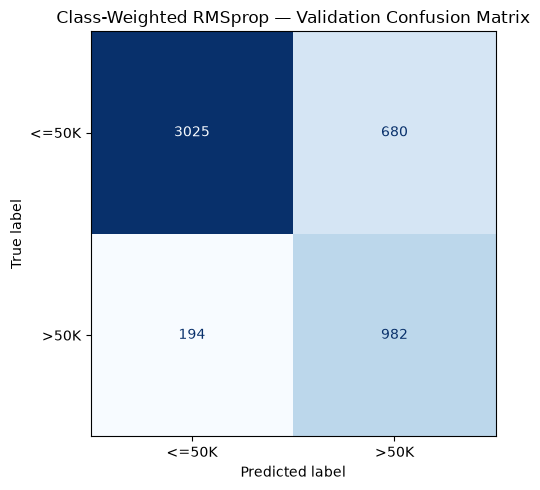

In [37]:
# Predict using the restored class-weighted checkpoint
weighted_val_probabilities = weighted_model.predict(
    X_val_processed,
    verbose=0
).ravel()

weighted_val_predictions = (
    weighted_val_probabilities >= THRESHOLD
).astype("int32")

weighted_val_metrics = {
    "validation_accuracy": accuracy_score(y_val, weighted_val_predictions),
    "validation_precision": precision_score(
        y_val, weighted_val_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, weighted_val_predictions, zero_division=0
    ),
    "validation_f1": f1_score(
        y_val, weighted_val_predictions, zero_division=0
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, weighted_val_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, weighted_val_probabilities
    )
}

# Compare all six configurations
model_comparison = pd.DataFrame(
    [
        small_val_metrics,
        larger_val_metrics,
        dropout_val_metrics,
        sgd_val_metrics,
        rmsprop_val_metrics,
        weighted_val_metrics
    ],
    index=[
        "Small MLP — Adam",
        "Larger MLP — Adam",
        "Larger MLP with dropout — Adam",
        "Small MLP — SGD with momentum",
        "Small MLP — RMSprop",
        "Small MLP — RMSprop weighted"
    ]
).sort_values("validation_f1", ascending=False)

display(model_comparison.round(4))

# Inspect how class weighting changed the errors
weighted_cm = confusion_matrix(
    y_val, weighted_val_predictions, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=weighted_cm,
    display_labels=["<=50K", ">50K"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Class-Weighted RMSprop — Validation Confusion Matrix")
plt.tight_layout()

# Save the evaluation in the existing weighted run
with mlflow.start_run(run_id=weighted_run_id):
    mlflow.log_param("prediction_threshold", THRESHOLD)
    mlflow.log_metrics(weighted_val_metrics)
    mlflow.log_figure(fig, "validation_confusion_matrix.png")

plt.show()

## Step 33 — Select the Model and Evaluate a Simple Baseline

### Selected model
Small MLP with RMSprop and balanced class weights:
- Architecture: 90 → 32 → 16 → 1
- Learning rate: 0.001
- Selected checkpoint: epoch 8
- Prediction threshold: 0.5
- Validation F1: 0.6920

### Why select it?
It achieved the highest validation F1 among our six tested
configurations, following our predefined selection rule.

Class weighting increased recall from 62.07% to 83.50%,
while reducing precision from 72.13% to 59.09%.

### Strongest counterargument
The unweighted model makes substantially fewer false alarms.
It could be preferable if incorrect higher-income predictions
were particularly costly.

Our choice assumes F1 is an appropriate assessment objective.
We have not demonstrated that it minimises a real business cost.

### Scope of the conclusion
This is the best observed configuration among our tested runs
at threshold 0.5.

We have not exhaustively tuned learning rates, thresholds or
architectures, or verified the ranking across multiple seeds.

### Why include a baseline?
A majority-class classifier always predicts the most common
training label. It uses no census relationships.

Evaluate it on the same validation records to show what our
neural network achieves beyond this simple guessing strategy.

### Final evaluation rule
Freeze the selected model and threshold before inspecting test
performance. Do not switch models based on the test results.

### Assessment explanation
“We selected the weighted RMSprop model because it achieved the
highest validation F1. We explicitly reported its lower precision
and greater number of false positives as the cost of higher recall.”

In [38]:
from sklearn.dummy import DummyClassifier

# Freeze the selected checkpoint and threshold
selected_model = weighted_model
selected_run_id = weighted_run_id
selected_model_name = "Small MLP — RMSprop weighted"
selected_threshold = THRESHOLD

# Learn the majority class from training labels only
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train_processed, y_train)

baseline_val_predictions = baseline_model.predict(X_val_processed)

positive_class_index = list(baseline_model.classes_).index(1)
baseline_val_probabilities = baseline_model.predict_proba(
    X_val_processed
)[:, positive_class_index]

baseline_val_metrics = {
    "validation_accuracy": accuracy_score(
        y_val, baseline_val_predictions
    ),
    "validation_precision": precision_score(
        y_val, baseline_val_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, baseline_val_predictions, zero_division=0
    ),
    "validation_f1": f1_score(
        y_val, baseline_val_predictions, zero_division=0
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, baseline_val_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, baseline_val_probabilities
    )
}

# Record the baseline separately from neural network runs
with mlflow.start_run(run_name="majority_class_baseline") as run:
    baseline_run_id = run.info.run_id
    mlflow.log_param("strategy", "most_frequent")
    mlflow.log_metrics(baseline_val_metrics)

baseline_comparison = pd.DataFrame(
    [baseline_val_metrics, weighted_val_metrics],
    index=["Majority-class baseline", selected_model_name]
)

display(baseline_comparison.round(4))

print("Selected model:", selected_model_name)
print("Frozen threshold:", selected_threshold)

,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision
Majority-class baseline,0.7591,0.0000,0.000,0.000,0.5000,0.2409
Small MLP — RMSprop weighted,0.8209,0.5909,0.835,0.692,0.9076,0.7766


Selected model: Small MLP — RMSprop weighted
Frozen threshold: 0.5


## Step 34 — Final Test Evaluation

### Frozen choices
- Model: small MLP with RMSprop and balanced class weights
- Checkpoint: epoch 8
- Classification threshold: 0.5
- Preprocessing: fitted on training data only

### Why evaluate on the test set?
Validation data influenced our model selection and early stopping.
The test records were held aside from those decisions.

Think of this as the final exam after studying and practice exams.

### What we will do
Compare the selected model's predictions with the actual test labels.
Report accuracy, precision, recall, F1, ROC-AUC and average precision.

Also evaluate the already-fitted majority-class baseline on the
same records to provide a direct reference.

### Decision
Keep the selected model and threshold unchanged after viewing results.
The test set evaluates our choice; it does not choose the winner.

We will evaluate the existing restored checkpoint without retraining.

### Limitation
This measures performance on held-out records from this dataset.
It does not establish performance on present-day census populations
or prove that the model is suitable for real decisions about people.

### Assessment explanation
“We selected the model using validation F1, froze its threshold,
and then evaluated it on a separate test set to estimate performance
on unseen records from the same dataset.”

,accuracy,precision,recall,f1,roc_auc,average_precision
Majority-class baseline,0.7591,0.0000,0.0000,0.0000,0.5000,0.2409
Small MLP — RMSprop weighted,0.8195,0.5885,0.8342,0.6901,0.9074,0.7784


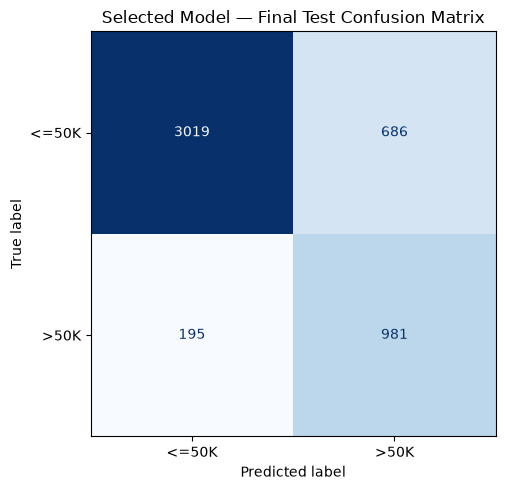

In [39]:
# Helper: calculate consistent metrics for any evaluated classifier
def calculate_metrics(actual, predictions, probabilities):
    return {
        "accuracy": accuracy_score(actual, predictions),
        "precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "f1": f1_score(
            actual, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(actual, probabilities),
        "average_precision": average_precision_score(
            actual, probabilities
        )
    }


# Evaluate the frozen neural network
test_probabilities = selected_model.predict(
    X_test_processed,
    verbose=0
).ravel()

test_predictions = (
    test_probabilities >= selected_threshold
).astype("int32")

test_metrics = calculate_metrics(
    y_test, test_predictions, test_probabilities
)

# Evaluate the existing baseline without fitting it again
baseline_test_predictions = baseline_model.predict(X_test_processed)

baseline_test_probabilities = baseline_model.predict_proba(
    X_test_processed
)[:, positive_class_index]

baseline_test_metrics = calculate_metrics(
    y_test,
    baseline_test_predictions,
    baseline_test_probabilities
)

# Compare baseline and selected model on the same test records
test_comparison = pd.DataFrame(
    [baseline_test_metrics, test_metrics],
    index=["Majority-class baseline", selected_model_name]
)

display(test_comparison.round(4))

# Display the selected model's final error counts
test_cm = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["<=50K", ">50K"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Selected Model — Final Test Confusion Matrix")
plt.tight_layout()

# Save final evaluation evidence to the selected model's run
with mlflow.start_run(run_id=selected_run_id):
    mlflow.set_tag("selected_model", "true")
    mlflow.set_tag("selection_rule", "validation_f1_at_threshold_0.5")
    mlflow.log_metrics({
        f"test_{name}": value
        for name, value in test_metrics.items()
    })
    mlflow.log_figure(fig, "test_confusion_matrix.png")

with mlflow.start_run(run_id=baseline_run_id):
    mlflow.log_metrics({
        f"test_{name}": value
        for name, value in baseline_test_metrics.items()
    })

plt.show()

## Step 35 — Save Models, Preprocessing and Results

### Final test findings
The selected model achieved:
- Accuracy: 81.95%
- Higher-income precision: 58.85%
- Higher-income recall: 83.42%
- F1: 0.6901
- ROC-AUC: 0.9074
- Average precision: 0.7784

It identified 981 higher-income records, missed 195,
and incorrectly labelled 686 lower-income records as higher-income.

Validation and test results were similar.

### Decision
Retain the selected checkpoint and threshold.
No further tuning will be based on these test results.

### What we will save
- All six trained neural network checkpoints.
- The fitted encoder and scaler.
- Input-column order and preparation instructions.
- Selected model name, MLflow run ID and threshold.
- Validation and test comparison tables.

### Why save preprocessing?
The network expects 90 prepared numerical inputs.
New records must use the same category columns, order and scaling
learned during training.

Re-fitting preprocessing on new records would change the meaning
of the model's inputs.

### Why save all six models?
This preserves the evaluated checkpoints and links them to their
MLflow experiments, supporting review and reproducibility.

### Assessment explanation
“We saved the trained checkpoints with their preprocessing and
decision threshold so predictions can be reproduced without
retraining or rebuilding the encoding.”

In [40]:
import json
import joblib

OUTPUT_DIR = PROJECT_DIR / "assessment_outputs"
MODEL_DIR = OUTPUT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the fitted preprocessing object once
preprocessor_path = OUTPUT_DIR / "preprocessor.joblib"
joblib.dump(preprocessor, preprocessor_path)

# Save each evaluated checkpoint and attach it to its MLflow run
trained_models = {
    "small_mlp_adam": (small_model, small_run_id),
    "larger_mlp_adam": (larger_model, larger_run_id),
    "larger_mlp_dropout_adam": (dropout_model, dropout_run_id),
    "small_mlp_sgd_momentum": (sgd_model, sgd_run_id),
    "small_mlp_rmsprop": (rmsprop_model, rmsprop_run_id),
    "small_mlp_rmsprop_weighted": (weighted_model, weighted_run_id)
}

for model_name, (model, run_id) in trained_models.items():
    model_path = MODEL_DIR / f"{model_name}.keras"
    model.save(model_path)

    with mlflow.start_run(run_id=run_id):
        mlflow.log_artifact(str(model_path), artifact_path="model_files")
        mlflow.log_artifact(
            str(preprocessor_path),
            artifact_path="preprocessing"
        )

    print("Saved:", model_path.name)

# Preserve prediction instructions and selected-model identity
prediction_metadata = {
    "selected_model": selected_model_name,
    "model_file": "models/small_mlp_rmsprop_weighted.keras",
    "preprocessor_file": "preprocessor.joblib",
    "mlflow_run_id": selected_run_id,
    "threshold": float(selected_threshold),
    "class_labels": {"0": "<=50K", "1": ">50K"},
    "input_columns": X_train.columns.tolist(),
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns,
    "processed_feature_names": preprocessor.get_feature_names_out().tolist(),
    "preparation": {
        "strip_text_whitespace": True,
        "question_mark_means_missing": True,
        "missing_category": "Unknown",
        "excluded_predictors": ["education", "fnlwgt"],
        "target_column": "income"
    }
}

metadata_path = OUTPUT_DIR / "prediction_metadata.json"
metadata_path.write_text(
    json.dumps(prediction_metadata, indent=2),
    encoding="utf-8"
)

# Save full-precision comparison results
validation_results_path = OUTPUT_DIR / "validation_comparison.csv"
test_results_path = OUTPUT_DIR / "test_comparison.csv"

model_comparison.to_csv(validation_results_path)
test_comparison.to_csv(test_results_path)

with mlflow.start_run(run_id=selected_run_id):
    for path in [
        metadata_path,
        validation_results_path,
        test_results_path
    ]:
        mlflow.log_artifact(str(path), artifact_path="assessment_results")

print("\nOutput folder:", OUTPUT_DIR)

Saved: small_mlp_adam.keras
Saved: larger_mlp_adam.keras
Saved: larger_mlp_dropout_adam.keras
Saved: small_mlp_sgd_momentum.keras
Saved: small_mlp_rmsprop.keras
Saved: small_mlp_rmsprop_weighted.keras

Output folder: C:\Saraswathi-DS\ds-october-2026-week2\assessment_outputs


## Step 36 — Verify the Saved Model

### What we will do
Reload the selected model, preprocessing object and metadata.
Use them to predict the same ten test records as before.

Compare:
- Prepared numerical inputs
- Predicted probability scores
- Predicted classes

### Why?
A successful save message does not establish that the saved files
work together correctly.

This check verifies that reloading preserves our prediction process.

### Decision
Use a small, fixed sample for this technical check.
We are not selecting or tuning a model using these records.

Load the neural network with compile=False because prediction
does not require restoring its training configuration.

### Assessment explanation
“We reloaded the saved model and preprocessing and verified that
they reproduced the original predictions within numerical tolerance.”

In [41]:
# Reload the saved prediction components
loaded_metadata = json.loads(
    (OUTPUT_DIR / "prediction_metadata.json").read_text(
        encoding="utf-8"
    )
)

loaded_preprocessor = joblib.load(
    OUTPUT_DIR / loaded_metadata["preprocessor_file"]
)

loaded_model = keras.models.load_model(
    OUTPUT_DIR / loaded_metadata["model_file"],
    compile=False
)

# Use the same ten records, preserving the required input order
sample_inputs = X_test.iloc[:10][
    loaded_metadata["input_columns"]
].copy()

# Apply saved preprocessing without fitting it again
loaded_sample_processed = loaded_preprocessor.transform(
    sample_inputs
).astype("float32")

# Verify preprocessing was preserved
np.testing.assert_allclose(
    loaded_sample_processed,
    X_test_processed[:10],
    rtol=1e-6,
    atol=1e-7
)

# Predict with the reloaded model
loaded_probabilities = loaded_model.predict(
    loaded_sample_processed,
    verbose=0
).ravel()

# Compare with probabilities from the original test evaluation
np.testing.assert_allclose(
    loaded_probabilities,
    test_probabilities[:10],
    rtol=1e-5,
    atol=1e-6
)

loaded_predictions = (
    loaded_probabilities >= loaded_metadata["threshold"]
).astype("int32")

np.testing.assert_array_equal(
    loaded_predictions,
    test_predictions[:10]
)

print("Saved preprocessing matches: PASSED")
print("Saved model probability scores match: PASSED")
print("Saved model predicted classes match: PASSED")

display(pd.DataFrame({
    "Original score": test_probabilities[:10],
    "Reloaded score": loaded_probabilities,
    "Predicted class": loaded_predictions,
    "Actual class": y_test.iloc[:10].to_numpy()
}).round(4))

Saved preprocessing matches: PASSED
Saved model probability scores match: PASSED
Saved model predicted classes match: PASSED


,Original score,Reloaded score,Predicted class,Actual class
0,0.0033,0.0033,0,0
1,0.0446,0.0446,0,0
2,0.0761,0.0761,0,0
3,0.0238,0.0238,0,0
4,0.4977,0.4977,0,1
5,0.5200,0.5200,1,0
6,0.0992,0.0992,0,0
7,0.0247,0.0247,0,0
8,0.0150,0.0150,0,0
9,0.5264,0.5264,1,0


## Step 37 — Open the MLflow Dashboard

### Verification finding
Reloading the saved preprocessing and selected model reproduced
the original inputs, prediction scores and classes.

### What the dashboard shows
- Experiments group related training attempts.
- Runs record individual attempts.
- Parameters describe the settings used.
- Metrics record measured performance.
- Artifacts contain saved files such as charts and model checkpoints.

### Why use it?
MLflow preserves the evidence behind our model selection.
It lets us compare configurations without relying on memory
or manually copied results.

### Important distinction
val_f1 was not recorded during each training epoch.
Our final restored-checkpoint F1 is named validation_f1.

Use validation_f1 to compare runs.
Use val_loss to inspect the validation training curve.

### Assessment explanation
“We tracked experiment settings, epoch metrics, final checkpoint
evaluations and artifacts in MLflow, providing an inspectable
record of how we selected the model.”

In [42]:
import tensorflow as tf

print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Available GPUs: []
